# Phasing and imputation with **SHAPEIT2** and **IMPUTE2**
### Practical workflow on human chromosome 22 (hg38), starting from the ANGSD VCF of the 1000 Genomes low-coverage lab

*Practical for the course "Genome-Wide Association Studies (GWAS) for Evolutionary Biology" (prstats.org)*

---

## Where are we in the course workflow?

```
 FASTQ  ──►  QC_Alignment_1000G_Colab.ipynb  ──►  bams/*.sorted.bam   (hg38)
                                                      │
                                                      ▼
                                 ANGSD_Lab_GoogleColab.ipynb  ──►  1000G.vcf.gz   (genotype likelihoods / posteriors)
                                                                        │
                                                                        ▼
                                        ► THIS NOTEBOOK ◄  phasing (SHAPEIT2) + imputation (IMPUTE2) on chr22
                                                                        │
                                                                        ▼
                                                       imputed, phased VCF  →  GWAS / selection scans / ...
```

Your input is `/content/drive/MyDrive/GWAS/1000G.vcf.gz`: the variant calls that ANGSD produced from
435 **very-low-coverage** whole-genome samples (5 populations: YRI, CEU, CHB, MXL, ASW) aligned to the hg38 reference.

## Learning objectives

After this practical you should be able to:

1. explain **why** we impute, and why imputation needs *haplotypes*, not just genotypes;
2. explain what **phasing** is, how the Li & Stephens copying model underlies both SHAPEIT2 and IMPUTE2, and what a **reference panel** adds;
3. prepare the files these programs need: **genetic map**, **haplotype / legend / sample** reference files, and a **harmonised** study file;
4. run the classical two-step pipeline **pre-phasing (SHAPEIT2) → imputation (IMPUTE2)**, in parallel chunks;
5. **evaluate** imputation honestly: accuracy by allele frequency, the IMPUTE2 `info` score and whether it is well calibrated, phasing switch-error rate;
6. know **which method to use for your own organism** and for low-coverage data (GLIMPSE, Beagle, ...), and what to do when no reference panel exists.

## How the notebook is organised

| Part | What happens |
|---|---|
| 0 | Background: the ideas behind phasing and imputation (read it, it is the “lecture”) |
| 1 | Install tools (conda), mount Drive, set parameters |
| 2 | Look at the ANGSD VCF, choose chr22, clean sample names |
| 3 | Get the **hg38 reference panel** and **genetic map**, prepare them, harmonise the study data |
| 4 | **Phasing** with SHAPEIT2 |
| 5 | **Imputation** with IMPUTE2 (chunks in parallel) |
| 6 | Collect results into a VCF |
| 7 | **Evaluation** against high-coverage truth |
| 8 | Discussion, limitations, modern alternatives, troubleshooting |

> **Runtime.** With the default settings (10 Mb of chr22, 2 CPUs of a free Colab VM) expect roughly **30–90 minutes** in total, most of
> it in IMPUTE2. All steps are *resumable*: if Colab disconnects, re-run the notebook from the top and finished steps are skipped.
> To go faster use `MAX_STUDY` (fewer samples) or a smaller region; to go for the whole chr22 set `FULL_CHROMOSOME = True`.

# Part 0 — Background

## 0.1 The problem: low coverage means uncertain genotypes

In the ANGSD lab you sequenced each sample to only a fraction of 1× (the “small FASTQs”). At a given site a typical
individual is covered by **0, 1 or 2 reads**. With one read showing allele `A` you cannot tell whether the genotype is `AA` or `AG`
(the second chromosome might simply not have been sampled). ANGSD therefore does not make hard genotype calls; it keeps the
**genotype likelihoods** (GL), i.e. `P(reads | genotype)` for the three genotypes `0/0, 0/1, 1/1`, and (with `-doPost 1`) combines them
with a prior (allele frequency in the whole sample, assuming Hardy–Weinberg) into **genotype posteriors** (GP).
That is what your `1000G.vcf.gz` contains (FORMAT field `GP`, and perhaps `GL`/`PL`).

Two things are missing from such data:

* **Certainty.** Most posteriors are close to the prior because there is almost no data per individual.
* **Sites.** Only sites that were *variable and well covered in this sample* (we required `-minInd 25 -minMaf 0.05`) are in the file.
  Rare variants, and sites nobody covered, are absent.

**Imputation** fixes both by *borrowing information from haplotypes in a reference panel*. Humans are not independent at nearby
sites: because of linkage disequilibrium (LD) a stretch of a few tens of kb is almost always a mosaic of a limited number of
haplotypes that are shared among people. If your sample carries the allele `A` at a few typed sites, it very likely
carries the same haplotype that the panel carries, and so you can “read off” the alleles at all the other sites on that haplotype —
including thousands of variants that you never sequenced.

## 0.2 Haplotypes and phasing

A **genotype** says how many copies of the alt allele an individual has at each site (`0/1`). A **haplotype** says which alleles sit together on the same chromosome (`0|1`, with the vertical bar meaning “phased”).

```
Individual with 4 heterozygous sites. Genotypes alone (unphased):  0/1  0/1  0/1  0/1
Possible haplotype pairs (2^(4-1) = 8):

   hap1: 0 0 0 0        hap1: 0 1 0 1      ...
   hap2: 1 1 1 1        hap2: 1 0 1 0
```

The number of possible phase assignments doubles with each heterozygous site, so phasing is a statistical inference problem.
**Statistical phasing** looks for the haplotype pair that is most plausible given that the other haplotypes in the sample (and the
reference panel) look like *mosaics of each other*. This is the **Li & Stephens (2003) copying model**:

> each haplotype is built by *copying* chunks from other haplotypes, with occasional switches between donors (≈ recombination;
> the switch probability depends on the genetic map distance and on the effective population size *N<sub>e</sub>*) and occasional
> mismatches (≈ mutation / genotyping error).

It is a **hidden Markov model** (HMM): the hidden state at each site is “which donor haplotype am I currently copying?”,
the emission says whether the allele matches the donor, and the transition says how likely a switch to another donor is between
two sites (large if the genetic distance is large). Forward-backward / sampling algorithms are used to get posterior probabilities.

**SHAPEIT2** (Delaneau et al. 2012, 2013) is an efficient implementation: it samples haplotype pairs for each individual conditioned on all the
other individuals (MCMC), but with a clever *haplotype-graph* representation so that the cost is linear in the number of samples, and
it can optionally condition on a **reference panel** of already-phased haplotypes to improve accuracy.

Important facts about phasing
* Phasing quality is measured by the **switch error rate (SER)**: at consecutive heterozygous sites, how often is the relative phase wrong?
  Modern large-sample phasing reaches SER of a fraction of a percent; with few hundred samples and no panel it is a few percent.
* More samples (and a reference panel of the same ancestry) → better phasing.
* Phasing needs a **genetic map** (cM per Mb) so that the HMM knows where switches are likely.
* SHAPEIT2 expects **genotypes** (hard calls), not likelihoods. We will therefore convert the ANGSD posteriors to hard calls and **drop calls that are uncertain**.
  (For truly low-coverage data this loses information. That is exactly why newer likelihood-aware methods exist, see section 0.6.)

## 0.3 Imputation with IMPUTE2

**IMPUTE2** (Howie, Donnelly & Marchini 2009; Howie et al. 2011) uses the same HMM idea, but now the *target* is a **study individual**
with typed genotypes at a subset of sites, and the *donors* are the reference panel haplotypes:

1. At the typed sites, the HMM computes which reference haplotypes match the study individual's haplotype (given the genetic map and *N<sub>e</sub>*).
2. At untyped sites, the posterior over the donor haplotype at the position is combined with the alleles carried by those donors,
   giving a **probability for each allele**, then for each genotype: `P(AA), P(AB), P(BB)` — a *genotype probability* rather than a hard call.
3. IMPUTE2 additionally **chooses, for every individual, the `k` most similar reference haplotypes** (`-k_hap`, default 500) to keep the computation tractable. Different individuals use different reference subsets.
4. The *a posteriori* certainty is summarised with the **`info` score** (a quantity between 0 and 1, similar to an r², measuring how much of the information
   one would have with perfectly known genotypes is retained) – used to filter badly imputed variants.

**Pre-phasing** (Howie et al. 2012) is the practical trick that makes the pipeline cheap:

```
(1) phase the study samples once  (SHAPEIT2 → .haps)             [expensive but done once, panel-independent]
(2) impute from the phased study haplotypes (IMPUTE2 -use_prephased_g)   [cheap, repeatable with any panel]
```

Why it works: in step 2 the study haplotype is already known (so the HMM has only *one* sequence of states to explain
instead of both haplotypes jointly) and you may re-impute later with a newer panel without redoing the phasing.

### The important IMPUTE2 parameters you will meet in the notebook

| Option | Meaning | Typical value |
|---|---|---|
| `-m` | genetic map file (cM/Mb and cumulative cM) – **must match the genome build** | hg38 map |
| `-h`, `-l` | reference **hap** and **legend** files | |
| `-known_haps_g` + `-use_prephased_g` | pre-phased study haplotypes (from SHAPEIT2) | |
| `-int start end` | region to impute (bp) – IMPUTE2 imputes **chunks**, ≲ 5 Mb recommended | 5 Mb |
| `-buffer` | extra kb on both sides of the chunk used as context (not output) | 250 kb |
| `-Ne` | effective population size, scales recombination probabilities | 20,000 (for human, as recommended in the manual) |
| `-k_hap` | number of reference haplotypes used per individual | 500 |
| `-seed` | random seed for reproducibility | |

## 0.4 Reference panels: what is needed and how do they look

A reference panel is a set of **phased haplotypes at all known variants** for a set of individuals. IMPUTE2 wants three files:

| File | Content |
|---|---|
| `*.hap.gz` | one row per variant, one column per haplotype (2 per individual), values `0`/`1`, space-separated |
| `*.legend.gz` | one row per variant: `id position a0 a1` (a0 = allele coded 0 = reference, a1 = allele coded 1 = alternative) |
| `*.sample` (SHAPEIT2 needs it) | one row per individual: `sample population group sex` |

For humans (**hg38**) the best publicly downloadable panel today is the **NYGC 1000 Genomes high-coverage (30×) phased callset**
(Byrska-Bishop et al. 2022, 3,202 individuals, 26 populations). It is distributed as phased VCFs per chromosome. We convert it to
IMPUTE2 format with `bcftools convert --haplegendsample`.

### Panel and study must be on the same footing
* **Same genome build.** An hg19 panel on hg38 coordinates is simply wrong. (This is why we aligned to hg38 and are using an hg38 panel.)
* **Same strand / same alleles.** Mismatches (the study says A/G, the panel says C/T) must be fixed or dropped.
* **Same contig naming**, `chr22` versus `22`. We will rename to `22` for these tools.
* **Matching ancestry.** Panels that contain the populations of the study give the best accuracy; 1000G includes all five of ours.

### The circularity problem (important for this *teaching* data set)
Our 435 study individuals **are themselves in the NYGC panel**. Imputing them from a panel that contains *themselves* would be cheating:
the HMM would find the identical haplotypes and the accuracy would be ~100%. Therefore in this practical we

1. **remove our study individuals from the panel** (the panel is then ≈ 2,770 individuals), and
2. use their **high-coverage genotypes from the NYGC callset as the truth** to measure how good the imputation from our *low-coverage* data is.

This is exactly the design you would use in a paper to benchmark an imputation pipeline (“leave-out” validation).
In a real project you would of course impute *new* individuals and have no truth.

## 0.5 What about my own organism? (the question of other species)

* **Can I impute without a species-specific panel?** Imputation needs *haplotypes of the same species (or a very close relative)*
  that capture the LD patterns. A human panel is **useless for a butterfly**: different genome, different variants, different LD.
  Options, from best to worst:
  1. a published **reference panel** for your species/population (livestock, model organisms, some crops and wild populations have them);
  2. **build your own panel**: sequence a subset of individuals (say 30–100) to *high* coverage (≥10–20×), call and phase them,
     and use them to impute the many low-coverage individuals – this is the standard “low-coverage + panel” design;
  3. **no external panel**: use **self-imputation / population-based imputation** inside the data set (Beagle, STITCH, or ANGSD-pipeline GL-aware imputation like `Beagle` in PCAngsd).
     This works well when the sample is large enough (hundreds of individuals) and the genome is not too recombinogenic; STITCH is the usual choice for low-coverage data without panel;
  4. a panel from a **closely related species** only for very close relatives and with big caveats (lift-over, much lower accuracy).
* **Can the human 1000G VCF be used as a stand-in for the practical?** Yes – *as human data*, which is why we use it here. It is not transferable to other organisms.
* **Two genome-build-related checks** to keep in mind everywhere: build (hg19/hg38), and chromosome naming.

## 0.6 Modern alternatives (and why we still teach SHAPEIT2 + IMPUTE2)

| Method | Notes |
|---|---|
| **GLIMPSE / GLIMPSE2** (Rubinacci et al. 2021) | imputes directly from **genotype likelihoods** (or BAMs) with a reference panel; the method of choice for low-coverage whole genome sequencing |
| **Beagle 5** (Browning et al.) | phasing + imputation in one; can use GL as input; fast; the usual choice for non-human data without license issues |
| **SHAPEIT4 / SHAPEIT5**, **Eagle2** | faster/more accurate phasing for large cohorts and biobanks (SHAPEIT4 is no longer maintained; SHAPEIT5 is its successor) |
| **STITCH**, **QUILT** | low-coverage imputation without or with a small reference panel; QUILT/QUILT2 use read-level information |
| **Minimac4** | pre-phased imputation, backbone of the Michigan and TOPMed imputation servers |
| **SHAPEIT2 + IMPUTE2** | the *classic* pre-phasing workflow (~2010–2016). Still instructive because every later method is a faster or more accurate version of the same Li & Stephens idea; and files (hap/legend/sample/gen) are still found everywhere. |

> **Licensing note.** SHAPEIT2 and IMPUTE2 are free for academic use but are *not* open-source (check the licence on the Oxford pages).
> They are also no longer developed. For production use, prefer the newer tools above.

# Part 1 — Setup: conda, software, Google Drive

Colab does not ship with bioinformatics software, so we first install **condacolab** (a mini-conda inside Colab).
This **restarts the Python kernel once** — that is expected; after the restart continue with the next cell (do not re-run this one).

In [1]:
# 1.1  Install conda inside Colab (kernel restarts automatically; ~30 s)
import os, sys, shutil
if shutil.which("mamba") or shutil.which("conda"):
    print("conda already available:", shutil.which("mamba") or shutil.which("conda"))
else:
    !pip install -q condacolab
    import condacolab
    condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:16
🔁 Restarting kernel...


In [1]:
# 1.2  Mount Google Drive (a pop-up asks for permission)
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1.3 Install the programs

| Program | Used for | Where from |
|---|---|---|
| `bcftools`, `htslib` (bgzip, tabix) | VCF handling, panel conversion | bioconda |
| `shapeit` (SHAPEIT2, v2.r904) | phasing | conda (`dnachun::shapeit2`), fallback: static binary from the Oxford web page |
| `impute2` (v2.3.2) | imputation | bioconda, fallback: static binary from the Oxford web page |
| `numpy`, `pandas`, `matplotlib` | evaluation and plots | conda-forge |

The cell below tries several sources for each tool and **reports clearly** which one worked. If everything fails for `shapeit` or `impute2`,
download the program yourself from the Oxford pages
(<https://mathgen.stats.ox.ac.uk/genetics_software/shapeit/shapeit.html> and <https://mathgen.stats.ox.ac.uk/impute/impute_v2.html>),
upload the executable to `/content/drive/MyDrive/GWAS/bin/` and re-run — the notebook will look there too.

In [2]:
# 1.3  Install the tools (conda first, static binaries as fallback)
import subprocess, shutil, os, time, glob

def sh(cmd, check=False):
    p = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    if check and p.returncode: raise RuntimeError(p.stdout + p.stderr)
    return p

CONDA = shutil.which("mamba") or shutil.which("conda")
print("package manager:", CONDA)

# general-purpose packages first
sh(f"{CONDA} install -y -q -c conda-forge -c bioconda bcftools htslib numpy pandas matplotlib scipy", check=False)

def have(*names):
    for n in names:
        w = shutil.which(n)
        if w: return w
    return None

BIN_DIR = "/content/bin"; os.makedirs(BIN_DIR, exist_ok=True)
os.environ["PATH"] = BIN_DIR + ":" + os.environ["PATH"]
USER_BIN = "/content/drive/MyDrive/GWAS/bin"      # optional: put your own executables here

def from_user_bin(patterns, link_as):
    for pat in patterns:
        for f in glob.glob(os.path.join(USER_BIN, pat)):
            os.chmod(f, 0o755); os.symlink(f, os.path.join(BIN_DIR, link_as)) if not os.path.exists(os.path.join(BIN_DIR, link_as)) else None
            return True
    return False

# ---------- IMPUTE2
if not have("impute2"):
    for ch in ["bioconda::impute2", "bioconda/label/main::impute2"]:
        sh(f"{CONDA} install -y -q -c conda-forge -c bioconda {ch}")
        if have("impute2"): break
if not have("impute2"):
    sh("cd /content && wget -q https://mathgen.stats.ox.ac.uk/impute/impute_v2.3.2_x86_64_static.tgz && tar xzf impute_v2.3.2_x86_64_static.tgz")
    f = glob.glob("/content/impute_v2.3.2_x86_64_static/impute2")
    if f: shutil.copy(f[0], BIN_DIR + "/impute2"); os.chmod(BIN_DIR + "/impute2", 0o755)
if not have("impute2"):
    from_user_bin(["impute2*", "impute_*"], "impute2")

# ---------- SHAPEIT2  (executable is called `shapeit`)
if not have("shapeit", "shapeit2"):
    for ch in ["dnachun::shapeit2", "bioconda::shapeit2", "bioconda::shapeit"]:
        sh(f"{CONDA} install -y -q -c conda-forge -c bioconda {ch}")
        if have("shapeit", "shapeit2"): break
if not have("shapeit", "shapeit2"):
    sh("cd /content && wget -q https://mathgen.stats.ox.ac.uk/genetics_software/shapeit/shapeit.v2.r904.glibcv2.17.linux.tar.gz && "
       "mkdir -p shapeit_dl && tar xzf shapeit.v2.r904.glibcv2.17.linux.tar.gz -C shapeit_dl")
    f = glob.glob("/content/shapeit_dl/**/shapeit", recursive=True)
    if f: shutil.copy(f[0], BIN_DIR + "/shapeit"); os.chmod(BIN_DIR + "/shapeit", 0o755)
if not have("shapeit", "shapeit2"):
    from_user_bin(["shapeit*"], "shapeit")

SHAPEIT = have("shapeit", "shapeit2")
IMPUTE2 = have("impute2")
BCFTOOLS = have("bcftools")
print(f"{'bcftools':10s}", BCFTOOLS)
print(f"{'shapeit':10s}", SHAPEIT)
print(f"{'impute2':10s}", IMPUTE2)
missing = [n for n, v in [("bcftools", BCFTOOLS), ("shapeit", SHAPEIT), ("impute2", IMPUTE2)] if not v]
if missing:
    raise SystemExit("Missing tools: %s  → see the instructions above (upload binaries to MyDrive/GWAS/bin/ and re-run)." % missing)
print(sh("bcftools --version | head -1").stdout.strip())
print((sh(f"{SHAPEIT} --version").stdout + sh(f"{SHAPEIT} --help").stdout)[:200].strip())
print(sh(f"{IMPUTE2} -h 2>&1 | head -5").stdout.strip())

package manager: /usr/local/bin/mamba
bcftools   /usr/local/bin/bcftools
shapeit    /usr/local/bin/shapeit
impute2    /usr/local/bin/impute2
bcftools 1.25
Segmented HAPlotype Estimation & Imputation Tool
  * Authors : Olivier Delaneau, Jared O'Connell, Jean-François Zagury, Jonathan Marchini
  * Contact : se
 IMPUTE version 2.3.2 


## 1.4 Parameters (everything you may want to change is here)

* **`REGION_START/END`** – region of chr22 to process. The default is 10 Mb in the middle of the chromosome (hg38 chr22 is ≈ 50.8 Mb long, and the first ≈ 10.5 Mb are unsequenced/centromeric).
  Set `FULL_CHROMOSOME = True` to process everything (≈ 4–5× longer).
* **`MAX_STUDY`** – use only the first *n* study samples (`None` = all 435). 100 samples is a good compromise for a teaching session.
* **`GP_CALL`** – minimum posterior probability of the best genotype for the ANGSD call to be kept as a hard genotype for phasing. Higher = fewer but more reliable genotypes (see Part 3.6).
* **`NE`, `BUFFER_KB`, `K_HAP`, `CHUNK_MB`** – IMPUTE2 settings explained in section 0.3.
* **`FORCE`** – `True` re-runs every step even if its output exists.

In [3]:
# 1.4  Parameters
import os, re, sys, gzip, json, math, time, shutil, subprocess, textwrap
from collections import Counter, OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE      = "/content/drive/MyDrive/GWAS"
VCF_IN    = f"{BASE}/1000G.vcf.gz"                 # ANGSD output from the previous lab
CHROM     = "chr22"                                  # contig name in the hg38 VCF
CHR       = "22"                                     # contig name used for SHAPEIT2/IMPUTE2 files

FULL_CHROMOSOME = False
REGION_START, REGION_END = 20_000_000, 30_000_000    # bp, hg38 coordinates (ignored if FULL_CHROMOSOME)
MAX_STUDY = 100                                       # None = all samples in the VCF

GP_CALL   = 0.90                                      # min GP of best genotype to keep a hard call
CHUNK_MB  = 5                                         # IMPUTE2 chunk size (Mb)
BUFFER_KB = 250
NE        = 20000
K_HAP     = 500
SEED      = 1234
N_THREADS = os.cpu_count() or 2
FORCE     = False

# folders: heavy temporary files on the fast local disk, small results + downloads cached on Drive
WORK   = "/content/imputation_chr22"
CACHE  = f"{BASE}/imputation_chr22_cache"           # panel / map downloads survive a Colab restart
OUTDIR = f"{BASE}/imputation_chr22_results"          # final tables, figures, VCF
for d in (WORK, CACHE, OUTDIR): os.makedirs(d, exist_ok=True)

CHR22_LEN_HG38 = 50_818_468
if FULL_CHROMOSOME:
    REGION_START, REGION_END = 1, CHR22_LEN_HG38
REGION = f"{CHROM}:{REGION_START}-{REGION_END}"
print("input VCF:", VCF_IN, "| exists:", os.path.exists(VCF_IN))
print("region   :", REGION, f"({(REGION_END-REGION_START+1)/1e6:.1f} Mb)")
print("threads  :", N_THREADS)

/usr/local/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


input VCF: /content/drive/MyDrive/GWAS/1000G.vcf.gz | exists: True
region   : chr22:20000000-30000000 (10.0 Mb)
threads  : 2


In [4]:
# 1.5  Small helpers: run a shell command with a log, and skip finished steps
def run(cmd, log=None, check=True, show=12, quiet=False):
    t0 = time.time()
    p = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    out = (p.stdout or "") + (p.stderr or "")
    if log:
        with open(log, "w") as fh: fh.write(out)
    if not quiet:
        c = " ".join(cmd.split())
        print("$", c if len(c) < 400 else c[:400] + " …")
        lines = out.strip().splitlines()
        if lines: print("\n".join(lines[-show:]))
        print(f"[{time.time()-t0:.1f} s, exit {p.returncode}]")
    if check and p.returncode != 0:
        raise RuntimeError(f"command failed (exit {p.returncode}):\n{cmd}\n--- last output ---\n" + "\n".join(out.strip().splitlines()[-25:]))
    return p

def done(*paths):
    # True if all files exist, are non-empty, and we are not forcing a re-run
    return (not FORCE) and all(os.path.exists(p) and os.path.getsize(p) > 0 for p in paths)

def nlines(path):
    op = gzip.open if path.endswith(".gz") else open
    with op(path, "rt") as fh:
        return sum(1 for _ in fh)
print("helpers ready")

helpers ready


# Part 2 — Look at the ANGSD VCF

Before using any file, **look at it**. Questions to answer: which contigs, how many samples, how are samples named, which FORMAT fields exist (GT? GL? GP?), and what do `REF`/`ALT` look like?

In [5]:
# 2.1  Header and first records
assert os.path.exists(VCF_IN), f"{VCF_IN} not found – check the path / that Drive is mounted"
if not os.path.exists(VCF_IN + ".tbi") and not os.path.exists(VCF_IN + ".csi"):
    run(f"bcftools index -t {VCF_IN}")                       # needs a bgzip-compressed file
r = run(f"bcftools view -h {VCF_IN} | grep -E '^##(FORMAT|INFO|contig|fileformat)' | head -25", show=40)
r = run(f"bcftools query -l {VCF_IN} | wc -l", show=2)
r = run(f"bcftools query -l {VCF_IN} | head -4", show=5)
r = run(f"bcftools view -H -r {CHROM} {VCF_IN} | head -3 | cut -f1-12", show=5)

$ bcftools view -h /content/drive/MyDrive/GWAS/1000G.vcf.gz | grep -E '^##(FORMAT|INFO|contig|fileformat)' | head -25
##fileformat=VCFv4.2
##contig=<ID=chr1,length=248956422>
##contig=<ID=chr10,length=133797422>
##contig=<ID=chr11,length=135086622>
##contig=<ID=chr11_KI270721v1_random,length=100316>
##contig=<ID=chr12,length=133275309>
##contig=<ID=chr13,length=114364328>
##contig=<ID=chr14,length=107043718>
##contig=<ID=chr14_GL000009v2_random,length=201709>
##contig=<ID=chr14_GL000225v1_random,length=211173>
##contig=<ID=chr14_KI270722v1_random,length=194050>
##contig=<ID=chr14_GL000194v1_random,length=191469>
##contig=<ID=chr14_KI270723v1_random,length=38115>
##contig=<ID=chr14_KI270724v1_random,length=39555>
##contig=<ID=chr14_KI270725v1_random,length=172810>
##contig=<ID=chr14_KI270726v1_random,length=43739>
##contig=<ID=chr15,length=101991189>
##contig=<ID=chr15_KI270727v1_random,length=448248>
##contig=<ID=chr16,length=90338345>
##contig=<ID=chr16_KI270728v1_random,length=187275

**What to look for in the output**

* `##FORMAT=<ID=GP,...>`: genotype **posteriors** from ANGSD `-doPost 1`. There may also be `GL` (log10 likelihoods).
  A hard-call `GT` may or may not be present, depending on the ANGSD version/options. We do **not** trust it: we make our own hard calls from `GP` (Part 3.6).
* **Sample names** are probably the BAM file names (e.g. `bams/HG00096.sorted.bam` or `HG00096.sorted.bam`). We need the plain 1000G sample ID (`HG00096`) to match the panel and the truth.
* **REF/ALT**: ANGSD without `-ref` takes *major / minor* alleles estimated from the data. It may therefore not equal the true hg38 reference allele. This is why we must **harmonise alleles** with the panel (Part 3.5).

In [6]:
# 2.2  Clean sample names (BAM file name → 1000G sample ID) and select study samples
raw = run(f"bcftools query -l {VCF_IN}", quiet=True).stdout.split()
def clean_id(s):
    m = re.search(r"(HG\d{5}|NA\d{5})", s)
    return m.group(1) if m else re.sub(r"(\.sorted)?\.(bam|cram)$", "", os.path.basename(s))
ids = [clean_id(s) for s in raw]
dups = [k for k, v in Counter(ids).items() if v > 1]
print(f"{len(raw)} samples in VCF; first raw name: {raw[0]!r} → {ids[0]!r}")
assert not dups, f"duplicate sample IDs after cleaning: {dups[:5]}"

keep_idx = list(range(len(raw)))
if MAX_STUDY and MAX_STUDY < len(raw):
    rng = np.random.default_rng(SEED)                      # random but reproducible subset
    keep_idx = sorted(rng.choice(len(raw), MAX_STUDY, replace=False).tolist())
STUDY = [ids[i] for i in keep_idx]
ALL_VCF_IDS = ids                                          # every study individual is removed from the panel later
print(f"study samples used: {len(STUDY)} (of {len(ids)});  e.g. {STUDY[:5]}")

with open(f"{WORK}/rename.txt", "w") as fh:               # bcftools reheader -s : one new name per line, in VCF order
    fh.write("\n".join(ids) + "\n")
with open(f"{WORK}/study_ids.txt", "w") as fh: fh.write("\n".join(STUDY) + "\n")
with open(f"{WORK}/all_vcf_ids.txt", "w") as fh: fh.write("\n".join(ids) + "\n")

435 samples in VCF; first raw name: '/content/drive/MyDrive/GWAS/bams/small.NA06984.mapped.ILLUMINA.bwa.CEU.low_coverage.20120522.sorted.bam' → 'NA06984'
study samples used: 100 (of 435);  e.g. ['NA06985', 'NA06989', 'NA11830', 'NA11832', 'NA11893']


In [7]:
# 2.3  Subset to the region, rename samples and contig, keep the study samples → study_raw.vcf.gz
STUDY_RAW = f"{WORK}/study_raw.vcf.gz"
if not done(STUDY_RAW):
    # 1) rename samples; 2) subset region + samples; (SHAPEIT2/IMPUTE2 contig name '22' is applied later)
    run(f"bcftools reheader -s {WORK}/rename.txt {VCF_IN} -o {WORK}/renamed.vcf.gz && bcftools index -t -f {WORK}/renamed.vcf.gz", show=3)
    run(f"bcftools view -r {REGION} -S {WORK}/study_ids.txt {WORK}/renamed.vcf.gz -Oz -o {STUDY_RAW} && bcftools index -t -f {STUDY_RAW}", show=3)
    os.remove(f"{WORK}/renamed.vcf.gz"); os.remove(f"{WORK}/renamed.vcf.gz.tbi")
n_raw = int(run(f"bcftools view -H {STUDY_RAW} | wc -l", quiet=True).stdout)
print(f"records in {REGION} for {len(STUDY)} study samples: {n_raw:,}")
fmt = run(f"bcftools view -h {STUDY_RAW} | grep -c '^##FORMAT'", quiet=True).stdout.strip()
print("FORMAT fields declared:", fmt, "| contains GP:", "ID=GP" in run(f"bcftools view -h {STUDY_RAW}", quiet=True).stdout)

$ bcftools reheader -s /content/imputation_chr22/rename.txt /content/drive/MyDrive/GWAS/1000G.vcf.gz -o /content/imputation_chr22/renamed.vcf.gz && bcftools index -t -f /content/imputation_chr22/renamed.vcf.gz
[0.3 s, exit 0]
$ bcftools view -r chr22:20000000-30000000 -S /content/imputation_chr22/study_ids.txt /content/imputation_chr22/renamed.vcf.gz -Oz -o /content/imputation_chr22/study_raw.vcf.gz && bcftools index -t -f /content/imputation_chr22/study_raw.vcf.gz
[0.1 s, exit 0]
records in chr22:20000000-30000000 for 100 study samples: 23
FORMAT fields declared: 13 | contains GP: True


### 2.4 Look at the data: how much information does the ANGSD VCF carry?

We stream the GP field and compute, per sample, the **maximum posterior** of the three genotypes. If most values are near the prior (≈ 0.5–0.9), little is known about that genotype.
This histogram tells us what to expect from the hard-call threshold `GP_CALL`.

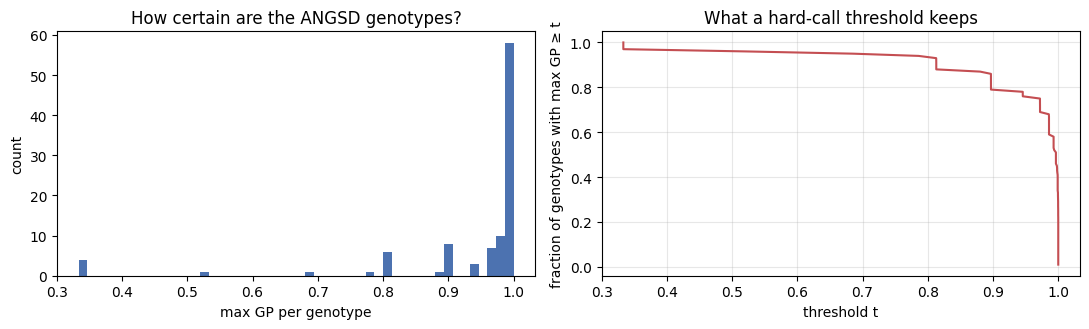

fraction of genotype calls with max GP ≥ 0.9: 78.00%


In [8]:
# 2.4  Streaming parser for GP (ANGSD GP = probabilities of REF/REF, REF/ALT, ALT/ALT)
def parse_gp(tok):
    # 'a,b,c' → np.array of 3 probabilities; missing/invalid → NaN
    try:
        v = np.array(tok.split(","), dtype=float)
    except ValueError:
        return np.full(3, np.nan)
    if v.size != 3 or not np.isfinite(v).all(): return np.full(3, np.nan)
    if (v < 0).any():                  # tolerate log-scale GP just in case
        v = np.exp(v - v.max())
    s = v.sum()
    return v / s if s > 0 else np.full(3, np.nan)

def iter_study(vcf, region=None):
    # yields (pos, ref, alt, GP matrix [n_samples × 3]) one site at a time via bcftools (no big memory)
    r = f"-r {region}" if region else ""
    cmd = f"bcftools query {r} -f '%POS\\t%REF\\t%ALT[\\t%GP]\\n' {vcf}"
    p = subprocess.Popen(cmd, shell=True, executable="/bin/bash", stdout=subprocess.PIPE, text=True)
    for line in p.stdout:
        f = line.rstrip("\n").split("\t")
        yield int(f[0]), f[1], f[2], np.array([parse_gp(t) for t in f[3:]])
    p.stdout.close(); p.wait()

maxgp, nsites = [], 0
for pos, ref, alt, gp in iter_study(STUDY_RAW):
    nsites += 1
    if nsites % 20 == 0: maxgp.append(np.nanmax(gp, axis=1))          # subsample every 20th site
    if nsites >= 20000: break
maxgp = np.concatenate(maxgp)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(maxgp[~np.isnan(maxgp)], bins=50, color="#4C72B0"); ax[0].set_xlabel("max GP per genotype"); ax[0].set_ylabel("count")
ax[0].set_title("How certain are the ANGSD genotypes?")
x = np.sort(maxgp[~np.isnan(maxgp)])
ax[1].plot(x, 1 - np.arange(len(x)) / len(x), color="#C44E52"); ax[1].set_xlabel("threshold t"); ax[1].set_ylabel("fraction of genotypes with max GP ≥ t")
ax[1].set_title("What a hard-call threshold keeps"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"fraction of genotype calls with max GP ≥ {GP_CALL}: {(x >= GP_CALL).mean():.2%}")

**Reading the plots.** With very low coverage the posterior is often dominated by the population-allele-frequency prior: at common sites many genotypes have max GP ~0.5–0.8, and only the lucky ones with several
reads reach 0.9. The right panel shows the trade-off: a high threshold gives *accurate but few* genotypes; a low threshold gives *many but noisy* ones.
Pre-phasing needs a decent number of **correct** typed genotypes per individual; imputation (the HMM) is fairly robust to missing typed genotypes but not to wrong ones.
We will measure this with the truth in Part 7.

# Part 3 — Reference panel, genetic map, and harmonisation

## 3.1 The NYGC 1000 Genomes 30× phased panel (hg38)

The panel is hosted by the EBI/IGSR FTP:

`https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/data_collections/1000G_2504_high_coverage/working/20220422_3202_phased_SNV_INDEL_SV/`

with one file per chromosome. The notebook **lists that directory and picks the chr22 file automatically** (file names have changed between releases).
If it fails (e.g. no internet or the server moved), set `PANEL_URL` manually in the next cell.
The VCF contains SNVs, indels and structural variants; we keep **biallelic SNVs** only (IMPUTE2 cannot use multi-allelic sites and mixing indels complicates allele matching).

In [9]:
# 3.1  Locate and download the chr22 panel VCF (cached on Drive; resumable)
import urllib.request
PANEL_URL = ""    # ← optionally paste a direct URL of the chr22 phased VCF(.gz) here
PANEL_DIR_URL = "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/data_collections/1000G_2504_high_coverage/working/20220422_3202_phased_SNV_INDEL_SV/"

def list_dir(url):
    with urllib.request.urlopen(url, timeout=60) as r:
        html = r.read().decode("utf8", "replace")
    return re.findall(r'href="([^"?/][^"]*)"', html)

if not PANEL_URL:
    files = list_dir(PANEL_DIR_URL)
    cand = [f for f in files if re.search(r"chr22\b", f) and f.endswith(".vcf.gz")]
    print("files mentioning chr22:", cand)
    assert cand, "chr22 panel file not found in the directory listing – set PANEL_URL manually"
    PANEL_URL = PANEL_DIR_URL + sorted(cand, key=len)[0]
PANEL_VCF = f"{CACHE}/" + os.path.basename(PANEL_URL)
print("panel:", PANEL_URL)
if not done(PANEL_VCF):
    run(f"curl -L --fail -C - -o {PANEL_VCF} {PANEL_URL}", show=3)
    run(f"curl -L --fail -o {PANEL_VCF}.tbi {PANEL_URL}.tbi", check=False, show=2)
print(f"size: {os.path.getsize(PANEL_VCF)/1e9:.2f} GB")
if not os.path.exists(PANEL_VCF + ".tbi"): run(f"bcftools index -t -f {PANEL_VCF}", show=2)
print(run(f"bcftools query -l {PANEL_VCF} | wc -l", quiet=True).stdout.strip(), "samples in panel;  contigs:",
      run(f"bcftools index -s {PANEL_VCF} | cut -f1 | head -3 | tr '\\n' ' '", quiet=True).stdout)

files mentioning chr22: ['1kGP_high_coverage_Illumina.chr22.filtered.SNV_INDEL_SV_phased_panel.vcf.gz']
panel: https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/data_collections/1000G_2504_high_coverage/working/20220422_3202_phased_SNV_INDEL_SV/1kGP_high_coverage_Illumina.chr22.filtered.SNV_INDEL_SV_phased_panel.vcf.gz
$ curl -L --fail -C - -o /content/drive/MyDrive/GWAS/imputation_chr22_cache/1kGP_high_coverage_Illumina.chr22.filtered.SNV_INDEL_SV_phased_panel.vcf.gz https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/data_collections/1000G_2504_high_coverage/working/20220422_3202_phased_SNV_INDEL_SV/1kGP_high_coverage_Illumina.chr22.filtered.SNV_INDEL_SV_phased_panel.vcf.gz
100 425.0M 100 425.0M   0      0 675.7k      0   10:44   10:44         777.2k
100 425.0M 100 425.0M   0      0 675.7k      0   10:44   10:44         777.2k
100 425.0M 100 425.0M   0      0 675.7k      0   10:44   10:44         777.2k
[644.2 s, exit 0]
$ curl -L --fail -o /content/drive/MyDrive/GWAS/imputation_chr22_cache/1kGP_hig

In [11]:
# 3.2  Population labels (optional; used only to stratify the evaluation)
POP_URL = "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/data_collections/1000G_2504_high_coverage/20130606_g1k_3202_samples_ped_population.txt"
POP_FILE = f"{CACHE}/samples_ped_population.txt"
if not done(POP_FILE): run(f"curl -L -s --fail -o {POP_FILE} {POP_URL}", check=False, show=2)
POP = {}
if os.path.exists(POP_FILE) and os.path.getsize(POP_FILE) > 0:
    ped = pd.read_csv(POP_FILE, sep=r"\s+")
    sid, pop = [c for c in ped.columns if c.lower() in ("sampleid", "individualid")][0], [c for c in ped.columns if c.lower() == "population"][0]
    POP = dict(zip(ped[sid], ped[pop]))
print("population labels available for", sum(s in POP for s in STUDY), "of", len(STUDY), "study samples")
print(Counter(POP.get(s, "NA") for s in STUDY))

population labels available for 100 of 100 study samples
Counter({'CEU': 25, 'YRI': 20, 'CHB': 20, 'MXL': 18, 'ASW': 17})


## 3.3 The genetic map (hg38)

The HMMs need the recombination rate along the chromosome. IMPUTE2/SHAPEIT2 format, three columns:

```
position COMBINED_rate(cM/Mb) Genetic_Map(cM)
 16050075 0.0000 0.0000
 16050408 3.1160 0.0010
```

Published **hg38** maps are available from several places (e.g. the SHAPEIT4/GLIMPSE `genetic_maps.b38` set, the Beagle PLINK-format maps for GRCh38). They carry
`position, chromosome, cM`; we convert them to the 3-column format by computing the rate between consecutive points.

> ⚠ The map **must match the genome build** of the data. hg19 maps on hg38 positions silently give wrong recombination rates (positions shift by up to Mb).

If *no* map can be downloaded, the cell falls back to a **flat map of 1 cM/Mb** – the programs still run, but accuracy is lower, especially for phasing; a warning is printed.

$ curl -L -s --fail -m 180 -o /content/imputation_chr22/mapdl_tar/m.tar https://github.com/odelaneau/shapeit4/raw/master/maps/genetic_maps.b38.tar.gz
curl: /usr/local/lib/libcurl.so.4: no version information available (required by curl)
[2.0 s, exit 0]
$ tar xzf /content/imputation_chr22/mapdl_tar/m.tar -C /content/imputation_chr22/mapdl_tar
[0.2 s, exit 0]
map source: shapeit4 repo (b38); 45,141 map points; chr22 total 74.1 cM; 15,287,922 – 50,791,377 bp


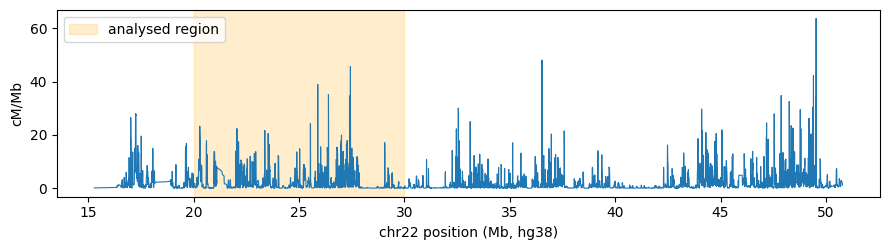

region covers 23.2 cM


In [12]:
# 3.3  Genetic map → IMPUTE2/SHAPEIT2 format
MAP_OUT = f"{CACHE}/genetic_map_chr{CHR}_hg38.txt"

def gmap_to_impute(df, pos_col, cm_col):
    # sort, drop duplicates / non-monotone cM, compute the local rate (cM/Mb)
    df = df[[pos_col, cm_col]].astype(float).dropna().sort_values(pos_col).drop_duplicates(pos_col)
    pos, cm = df[pos_col].to_numpy(), df[cm_col].to_numpy()
    cm = np.maximum.accumulate(cm)                                  # cM must not decrease
    dp = np.diff(pos, prepend=pos[0]); dc = np.diff(cm, prepend=cm[0])
    rate = np.divide(dc * 1e6, dp, out=np.zeros_like(dc), where=dp > 0)
    # the rate is attributed to the interval *ending* at each position; IMPUTE2 wants rate to the next → shift
    rate = np.append(rate[1:], rate[-1] if len(rate) else 0.0)
    return pd.DataFrame({"position": pos.astype(int), "COMBINED_rate(cM/Mb)": rate, "Genetic_Map(cM)": cm})

def read_any_map(path):
    op = gzip.open if path.endswith(".gz") else open
    with op(path, "rt") as fh: head = fh.readline().split()
    low = [h.lower() for h in head]
    if {"pos", "cm"} <= set(low):                                   # SHAPEIT4/GLIMPSE style: pos chr cM
        df = pd.read_csv(path, sep=r"\s+")
        df.columns = [c.lower() for c in df.columns]
        return gmap_to_impute(df, "pos", "cm")
    if "position" in low and any("genetic" in h for h in low):      # already IMPUTE2 style
        df = pd.read_csv(path, sep=r"\s+"); return gmap_to_impute(df, df.columns[0], df.columns[2])
    df = pd.read_csv(path, sep=r"\s+", header=None)                 # PLINK-style: chr id cM bp
    return gmap_to_impute(df, 3, 2)

MAP_SOURCES = [
    # (name, URL, how to extract)
    ("shapeit4 repo (b38)", "https://github.com/odelaneau/shapeit4/raw/master/maps/genetic_maps.b38.tar.gz", "tar"),
    ("beagle GRCh38 plink maps", "https://bochet.gcc.biostat.washington.edu/beagle/genetic_maps/plink.GRCh38.map.zip", "zip"),
]
MAP_SOURCE_USED = None
if not done(MAP_OUT):
    for name, url, kind in MAP_SOURCES:
        try:
            d = f"{WORK}/mapdl_{kind}"; shutil.rmtree(d, ignore_errors=True); os.makedirs(d)
            arc = f"{d}/m.{kind}"
            run(f"curl -L -s --fail -m 180 -o {arc} {url}", show=2)
            run(("tar xzf " if kind == "tar" else "unzip -q -o ") + arc + (" -C " if kind == "tar" else " -d ") + d, show=2)
            hits = [f for f in glob.glob(d + "/**/*", recursive=True)
                    if re.search(rf"(chr{CHR}\b|chr{CHR}[._]|\.chr{CHR}\.|plink\.chr{CHR}\.)", os.path.basename(f)) and os.path.isfile(f)]
            assert hits, "no chr22 file inside archive"
            m = read_any_map(sorted(hits, key=len)[0])
            m.to_csv(MAP_OUT, sep=" ", index=False)
            MAP_SOURCE_USED = name; break
        except Exception as e:
            print(f"  map source '{name}' failed: {str(e)[:150]}")
    if MAP_SOURCE_USED is None:
        print("⚠⚠  No genetic map could be downloaded – using a FLAT map of 1 cM/Mb. Results will be somewhat worse.")
        pos = np.arange(1, CHR22_LEN_HG38, 100_000)
        pd.DataFrame({"position": pos, "COMBINED_rate(cM/Mb)": 1.0, "Genetic_Map(cM)": (pos - 1) / 1e6}).to_csv(MAP_OUT, sep=" ", index=False)
        MAP_SOURCE_USED = "flat 1 cM/Mb"
gm = pd.read_csv(MAP_OUT, sep=" ")
print(f"map source: {MAP_SOURCE_USED or 'cached file'}; {len(gm):,} map points; chr22 total {gm.iloc[-1,2]:.1f} cM; "
      f"{gm.iloc[0,0]:,} – {gm.iloc[-1,0]:,} bp")
reg = gm[(gm.position >= REGION_START) & (gm.position <= REGION_END)]
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(gm.position / 1e6, gm["COMBINED_rate(cM/Mb)"].rolling(20, min_periods=1).mean(), lw=.8)
ax.axvspan(REGION_START / 1e6, REGION_END / 1e6, color="orange", alpha=.2, label="analysed region")
ax.set_xlabel("chr22 position (Mb, hg38)"); ax.set_ylabel("cM/Mb"); ax.legend(); plt.tight_layout(); plt.show()
print(f"region covers {reg['Genetic_Map(cM)'].max()-reg['Genetic_Map(cM)'].min():.1f} cM")

## 3.4 Prepare the panel: select the region, remove the study samples, keep biallelic SNVs, convert to hap/legend/sample

`bcftools view` options used:

* `-r REGION` – region (needs the index);
* `-S ^file` – **exclude** the samples listed in the file (the caret negates) → *this removes all 435 study individuals from the panel*, not just the ones we use;
* `-m2 -M2 -v snps` – only bi-allelic SNVs;
* `-c 1:minor` – keep sites that still have at least one copy of the minor allele after removing samples (monomorphic sites are useless).

Then `bcftools annotate --rename-chrs` changes `chr22` → `22`, and `bcftools convert --haplegendsample` writes the three IMPUTE2 files.
We also write a second copy of the genotypes of the **study** individuals (the truth, `truth.vcf.gz`) from the same panel VCF.

In [13]:
# 3.4  Panel preparation
REF_PREFIX = f"{WORK}/ref_chr{CHR}"
TRUTH_VCF  = f"{WORK}/truth.vcf.gz"
with open(f"{WORK}/chrmap.txt", "w") as fh: fh.write(f"{CHROM}\t{CHR}\n")
with open(f"{WORK}/chrmap_back.txt", "w") as fh: fh.write(f"{CHR}\t{CHROM}\n")

panel_samples = set(run(f"bcftools query -l {PANEL_VCF}", quiet=True).stdout.split())
n_in_panel = sum(s in panel_samples for s in ALL_VCF_IDS)
print(f"{n_in_panel} of the {len(ALL_VCF_IDS)} ANGSD-VCF individuals are in the panel → they will be removed from it")
missing_truth = [s for s in STUDY if s not in panel_samples]
if missing_truth:
    print(f"⚠ {len(missing_truth)} study samples have no truth genotypes in the panel (they will be imputed but not evaluated)")
with open(f"{WORK}/remove_from_panel.txt", "w") as fh:
    fh.write("\n".join([s for s in ALL_VCF_IDS if s in panel_samples]) + "\n")
with open(f"{WORK}/truth_ids.txt", "w") as fh:
    fh.write("\n".join([s for s in STUDY if s in panel_samples]) + "\n")

if not done(f"{REF_PREFIX}.hap.gz", f"{REF_PREFIX}.legend.gz", f"{REF_PREFIX}.samples"):
    run(f"bcftools view -r {REGION} -S ^{WORK}/remove_from_panel.txt -m2 -M2 -v snps -c 1:minor {PANEL_VCF} -Ou "
        f"| bcftools annotate --rename-chrs {WORK}/chrmap.txt -x ID -Oz -o {WORK}/panel_region.vcf.gz && bcftools index -t -f {WORK}/panel_region.vcf.gz", show=3)
    # NB: we drop the ID column (-x ID) so legend IDs are generated as CHR:POS_REF_ALT by bcftools convert
    run(f"bcftools convert --haplegendsample {REF_PREFIX} {WORK}/panel_region.vcf.gz", show=3)
if not done(TRUTH_VCF):
    run(f"bcftools view -r {REGION} -S {WORK}/truth_ids.txt -m2 -M2 -v snps {PANEL_VCF} -Ou "
        f"| bcftools annotate --rename-chrs {WORK}/chrmap.txt -x ID,INFO -Oz -o {TRUTH_VCF} && bcftools index -t -f {TRUTH_VCF}", show=3)
for f in (f"{REF_PREFIX}.hap.gz", f"{REF_PREFIX}.legend.gz", f"{REF_PREFIX}.samples"):
    print(f"{os.path.basename(f):28s}", f"{os.path.getsize(f)/1e6:8.1f} MB")
n_ref = nlines(f"{REF_PREFIX}.legend.gz") - 1
n_hapcols = len(gzip.open(f"{REF_PREFIX}.hap.gz", "rt").readline().split())
print(f"panel: {n_ref:,} SNVs × {n_hapcols} haplotypes ({n_hapcols//2} individuals)")
print(gzip.open(f"{REF_PREFIX}.legend.gz", "rt").read(240))

435 of the 435 ANGSD-VCF individuals are in the panel → they will be removed from it
$ bcftools view -r chr22:20000000-30000000 -S ^/content/imputation_chr22/remove_from_panel.txt -m2 -M2 -v snps -c 1:minor /content/drive/MyDrive/GWAS/imputation_chr22_cache/1kGP_high_coverage_Illumina.chr22.filtered.SNV_INDEL_SV_phased_panel.vcf.gz -Ou | bcftools annotate --rename-chrs /content/imputation_chr22/chrmap.txt -x ID -Oz -o /content/imputation_chr22/panel_region.vcf.gz && bcftools index - …
[W::bcf_hdr_check_sanity] AC should be declared as Number=A
[W::bcf_hdr_check_sanity] AC should be declared as Number=A
[131.2 s, exit 0]
$ bcftools convert --haplegendsample /content/imputation_chr22/ref_chr22 /content/imputation_chr22/panel_region.vcf.gz
Legend file: /content/imputation_chr22/ref_chr22.legend.gz
Sample file: /content/imputation_chr22/ref_chr22.samples
239243 records written, 0 skipped: 0/0/0 no-ALT/non-biallelic/filtered
[97.6 s, exit 0]
$ bcftools view -r chr22:20000000-30000000 -S /co

## 3.5 Harmonise the study genotypes with the panel

For every ANGSD site in the region we need to decide: **is it in the panel with the same alleles?** Four outcomes:

| Situation | Example (study REF/ALT vs panel a0/a1) | Action |
|---|---|---|
| **identical** | `A/G` vs `A/G` | keep |
| **swapped** | `G/A` vs `A/G` (ANGSD's *major/minor* ≠ hg38 REF/ALT) | keep, but **swap alleles and genotype posteriors** (0/0 ↔ 1/1) |
| **different alleles** | `A/C` vs `A/G` | drop (could be a different variant or a strand/ID problem) |
| **not in panel** | – | drop (IMPUTE2 only uses typed SNPs that the panel knows about) |

Our study and panel are both **hg38, forward strand**, so *strand flips* are not expected; for data from arrays (where strand may differ) you would also test the complement `A↔T, C↔G`, and have to drop the A/T and C/G ambiguous SNPs. Here we do not flip, we just count mismatches (a large number would indicate a build or strand issue).

Then we make **hard calls**: the genotype with the highest posterior if it is ≥ `GP_CALL`, otherwise missing (`./.`). The result is a plain GT-only VCF, which SHAPEIT2 reads.

In [14]:
# 3.5  Harmonise alleles and make hard calls
def load_panel_alleles(legend_gz):
    d, dup = {}, set()
    with gzip.open(legend_gz, "rt") as fh:
        next(fh)
        for line in fh:
            _id, pos, a0, a1 = line.split()[:4]
            pos = int(pos)
            if pos in d: dup.add(pos)
            d[pos] = (a0, a1)
    for p in dup: d.pop(p, None)                 # same position twice → ambiguous, ignore
    return d

def harmonise_to_vcf(study_vcf, panel_alleles, out_vcf, samples, gp_call, chrom_out):
    # Write GT-only VCF with panel REF/ALT; returns a dict of counts and per-site call rates
    GT = np.array(["0/0", "0/1", "1/1", "./."])
    stats = Counter(); kept_pos = []
    with open(out_vcf, "w") as out:
        out.write("##fileformat=VCFv4.2\n")
        out.write('##FORMAT=<ID=GT,Number=1,Type=String,Description="Genotype">\n')
        out.write(f"##contig=<ID={chrom_out}>\n")
        out.write("#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\tFORMAT\t" + "\t".join(samples) + "\n")
        for pos, ref, alt, gp in iter_study(study_vcf):
            stats["study_sites"] += 1
            pa = panel_alleles.get(pos)
            if pa is None: stats["not_in_panel"] += 1; continue
            a0, a1 = pa
            if (ref, alt) == (a0, a1): swap = False; stats["identical"] += 1
            elif (ref, alt) == (a1, a0): swap = True; stats["swapped"] += 1
            else: stats["allele_mismatch"] += 1; continue
            if swap: gp = gp[:, ::-1]                                  # (RR,RA,AA) → (AA,RA,RR)
            best = np.nanargmax(np.where(np.isnan(gp), -1, gp), axis=1)
            ok = (~np.isnan(gp).any(axis=1)) & (gp.max(axis=1, initial=0) >= gp_call)
            g = np.where(ok, best, 3)
            stats["calls_total"] += len(g); stats["calls_kept"] += int(ok.sum())
            out.write(f"{chrom_out}\t{pos}\t{chrom_out}:{pos}_{a0}_{a1}\t{a0}\t{a1}\t.\t.\t.\tGT\t" + "\t".join(GT[g]) + "\n")
            kept_pos.append(pos)
    return stats, kept_pos

TYPED_VCF = f"{WORK}/typed_hardcalls.vcf"
if not done(TYPED_VCF + ".gz"):
    pa = load_panel_alleles(f"{REF_PREFIX}.legend.gz")
    stats, kept = harmonise_to_vcf(STUDY_RAW, pa, TYPED_VCF, STUDY, GP_CALL, CHR)
    run(f"bgzip -f {TYPED_VCF} && bcftools index -t -f {TYPED_VCF}.gz", show=2)
    json.dump({**stats, "positions": kept}, open(f"{WORK}/harmonise_stats.json", "w"))
else:
    stats = json.load(open(f"{WORK}/harmonise_stats.json")); kept = stats.pop("positions")
print(pd.Series({k: v for k, v in stats.items()}).to_frame("count").T.to_string())
print(f"\nsites kept for phasing/imputation : {len(kept):,} ({len(kept)/max(stats['study_sites'],1):.1%} of ANGSD sites)")
print(f"hard-call rate at kept sites      : {stats['calls_kept']/max(stats['calls_total'],1):.1%} of genotypes (GP ≥ {GP_CALL})")
print(f"typed density                      : 1 typed SNV per {(REGION_END-REGION_START)/max(len(kept),1):,.0f} bp;  panel has 1 per {(REGION_END-REGION_START)/max(n_ref,1):,.0f} bp")

$ bgzip -f /content/imputation_chr22/typed_hardcalls.vcf && bcftools index -t -f /content/imputation_chr22/typed_hardcalls.vcf.gz
[0.0 s, exit 0]
       study_sites  swapped  calls_total  calls_kept  identical  not_in_panel
count           23        3         2100        1538         18             2

sites kept for phasing/imputation : 21 (91.3% of ANGSD sites)
hard-call rate at kept sites      : 73.2% of genotypes (GP ≥ 0.9)
typed density                      : 1 typed SNV per 476,190 bp;  panel has 1 per 42 bp


**What to expect.** The ANGSD sites (MAF ≥ 5%, high-confidence) are only a small subset of the panel's variants (≈ 10–30%): this is exactly the “genotyped on an array” situation.
Imputation will have to fill in the rest (mostly rarer variants). If `allele_mismatch` is more than a few percent, something is wrong (e.g. different build or the VCF has been produced with a `-ref` that
used another allele naming) and you should stop and investigate before continuing.

# Part 4 — Phasing with SHAPEIT2

## 4.1 The pipeline in two SHAPEIT2 commands

1. **`shapeit -check`** compares the study data with the reference panel *before* phasing: are the alleles consistent? are there SNPs that exist in the study but not in the panel? It writes lists of SNPs that
   must be excluded. *Always run this step* – it catches strand and build mistakes early.
2. **`shapeit`** (the phasing itself) – options we use:

| Option | Meaning |
|---|---|
| `--input-vcf` | study genotypes (hard calls) |
| `--input-map` | genetic map (3-column format) |
| `--input-ref hap legend sample` | **reference-assisted phasing**: the panel haplotypes are used as additional donors |
| `--exclude-snp` | SNPs flagged by `-check` |
| `--effective-size 20000` | Ne for the copying model |
| `--thread` | CPU threads |
| `--output-max haps sample` | write the **maximum-likelihood haplotypes** (the “best guess” phase) – this is what IMPUTE2 reads |
| `--seed` | reproducibility |

Internally SHAPEIT2 runs an MCMC with *burn-in*, *pruning* and *main* iterations (defaults 7 / 8 / 20 iterations; `--burn --prune --main`) and a number of conditioning states per individual (`--states`, default 100).
More iterations/states = slightly better, slower.

**Why also phase with the reference?** Our 100–435 samples alone give a rough phase; haplotypes from ~2,700 reference individuals give the HMM many more good donors.
(If you want to see the effect, set `PHASE_WITH_REF = False` and compare the switch error rate in Part 7.)

In [15]:
# 4.2  Run SHAPEIT2: check, then phase
PHASE_WITH_REF = True
PHASED = f"{WORK}/phased"                          # → phased.haps / phased.sample
MAP_FILE = MAP_OUT
ref_args = f"--input-ref {REF_PREFIX}.hap.gz {REF_PREFIX}.legend.gz {REF_PREFIX}.samples" if PHASE_WITH_REF else ""

def shapeit_input(fmt_gz=True):
    return f"--input-vcf {WORK}/typed_hardcalls.vcf" + (".gz" if fmt_gz else "")

if not done(PHASED + ".haps", PHASED + ".sample"):
    # --- (a) consistency check against the panel
    if PHASE_WITH_REF:
        r = run(f"{SHAPEIT} -check {shapeit_input()} --input-map {MAP_FILE} {ref_args} --output-log {WORK}/shapeit_check", check=False, show=25)
        if r.returncode != 0:                                  # some builds cannot read .vcf.gz → plain text VCF
            run(f"bgzip -dc {WORK}/typed_hardcalls.vcf.gz > {WORK}/typed_hardcalls.vcf", show=2)
            r = run(f"{SHAPEIT} -check {shapeit_input(False)} --input-map {MAP_FILE} {ref_args} --output-log {WORK}/shapeit_check", check=False, show=25)
        excl = f"{WORK}/shapeit_check.snp.strand.exclude"
        for cand in (excl, f"{WORK}/shapeit_check.alignments.snp.strand.exclude"):
            if os.path.exists(cand): excl = cand; break
        n_ex = nlines(excl) if os.path.exists(excl) else 0
        print(f"SNPs to exclude after -check: {n_ex}")
        excl_arg = f"--exclude-snp {excl}" if n_ex else ""
    else:
        excl_arg = ""
    # --- (b) phase
    base = (f"{SHAPEIT} {{inp}} --input-map {MAP_FILE} {ref_args} {excl_arg} --effective-size {NE} "
            f"--thread {N_THREADS} --seed {SEED} --force --output-max {PHASED}.haps {PHASED}.sample --output-log {WORK}/shapeit_phase")
    t0 = time.time()
    r = run(base.format(inp=shapeit_input()), check=False, show=15)
    if r.returncode != 0 or not os.path.exists(PHASED + ".haps"):
        if not os.path.exists(f"{WORK}/typed_hardcalls.vcf"):
            run(f"bgzip -dc {WORK}/typed_hardcalls.vcf.gz > {WORK}/typed_hardcalls.vcf", show=2)
        r = run(base.format(inp=shapeit_input(False)), check=True, show=15)
    print(f"phasing took {time.time()-t0:.0f} s")
assert os.path.exists(PHASED + ".haps"), "SHAPEIT2 did not produce .haps – see shapeit_phase.log in " + WORK
print(open(PHASED + ".sample").read().splitlines()[:4])
print("haps columns (5 annotation + 2 per individual):", len(open(PHASED + ".haps").readline().split()))
print(open(PHASED + ".haps").readline()[:120], "…")

$ /usr/local/bin/shapeit -check --input-vcf /content/imputation_chr22/typed_hardcalls.vcf.gz --input-map /content/drive/MyDrive/GWAS/imputation_chr22_cache/genetic_map_chr22_hg38.txt --input-ref /content/imputation_chr22/ref_chr22.hap.gz /content/imputation_chr22/ref_chr22.legend.gz /content/imputation_chr22/ref_chr22.samples --output-log /content/imputation_chr22/shapeit_check

Reading unphased data in [/content/imputation_chr22/typed_hardcalls.vcf.gz]
  * 100 samples included
  * 100 unrelateds / 0 duos / 0 trios in 100 different families
  * 21 SNPs included

Reading sample list [/content/imputation_chr22/ref_chr22.samples]
  * Column gender detected (idx=3)
  * 5534 reference haplotypes included
  * 0 males / 2767 females

Reading SNPs in [/content/imputation_chr22/ref_chr22.legend.gz]
  * 21 reference panel sites included
  * 239222 reference panel sites excluded

Reading reference haplotypes in [/content/imputation_chr22/ref_chr22.hap.gz]

Reading genetic map in [/content/drive/M

### 4.3 The output files

* `phased.haps` – one line per typed SNP: `chr  snp_id  position  allele0  allele1  h1_s1 h2_s1 h1_s2 h2_s2 …` where haplotype values are `0` (= allele0) or `1` (= allele1).
  Missing hard calls (`./.` from low GP) have been **filled in** by the model — phasing and genotype imputation at *typed* sites happen simultaneously.
* `phased.sample` – the individuals, in the same order as the columns in `.haps`.

**Question for students.** The `-check` step reports SNPs to exclude. Why might the study allele pair not match the panel pair, even though both are hg38? *(Hint: look at how ANGSD chooses REF/ALT.)*

# Part 5 — Imputation with IMPUTE2

## 5.1 Chunking

IMPUTE2 is not designed to run on a whole chromosome at once:
* memory and time grow with the region size; the program refuses regions > 7 Mb unless `-allow_large_regions` is given (we use ≤ 5 Mb anyway);
* **chunks are independent**, so they can run in parallel.

Each chunk `[start, end]` is imputed using SNPs in `[start − buffer, end + buffer]` as context, but only the genotypes inside `[start, end]` are written. The buffer prevents edge effects
(near the chunk boundary the HMM would otherwise have only one-sided information). Chunks must **not overlap**, otherwise variants would be written twice.

## 5.2 The command

```
impute2 -use_prephased_g -known_haps_g phased.haps \
        -h ref.hap.gz -l ref.legend.gz -m genetic_map.txt \
        -int START END -Ne 20000 -buffer 250 -k_hap 500 -seed 1234 \
        -o chunk.gen
```

Outputs per chunk: `chunk.gen` (genotype probabilities for every SNP: `snp_id rs_id pos a0 a1  P(a0a0) P(a0a1) P(a1a1)` for each individual), `chunk.gen_info` (per-SNP metrics incl. `info`), `chunk.gen_summary`, `chunk.gen_warnings`.

In [16]:
# 5.3  Define the chunks and run IMPUTE2 (a few chunks in parallel)
CHUNK = CHUNK_MB * 1_000_000
chunks = []
s = REGION_START
while s <= REGION_END:
    e = min(s + CHUNK - 1, REGION_END)
    chunks.append((s, e)); s = e + 1
print(f"{len(chunks)} chunk(s):", [(a/1e6, b/1e6) for a, b in chunks])

N_PAR = 2 if N_THREADS >= 2 else 1                       # IMPUTE2 is single-threaded; 2 parallel jobs on a 2-CPU Colab VM
IMPDIR = f"{WORK}/impute"; os.makedirs(IMPDIR, exist_ok=True)

def chunk_prefix(i, a, b): return f"{IMPDIR}/chunk{i:02d}_{a}_{b}"
def impute_cmd(i, a, b):
    pre = chunk_prefix(i, a, b)
    return (f"{IMPUTE2} -use_prephased_g -known_haps_g {PHASED}.haps -h {REF_PREFIX}.hap.gz -l {REF_PREFIX}.legend.gz "
            f"-m {MAP_FILE} -int {a} {b} -Ne {NE} -buffer {BUFFER_KB} -k_hap {K_HAP} -seed {SEED} -allow_large_regions -o {pre}.gen")

def chunk_ok(i, a, b):
    pre = chunk_prefix(i, a, b)
    return (not FORCE) and os.path.exists(pre + ".gen_info") and os.path.exists(pre + ".done")

todo = [(i, a, b) for i, (a, b) in enumerate(chunks) if not chunk_ok(i, a, b)]
timings = json.load(open(f"{WORK}/impute_timings.json")) if os.path.exists(f"{WORK}/impute_timings.json") else {}
running = []
def reap(block=False):
    for item in list(running):
        i, a, b, p, t0 = item
        if p.poll() is None and not block: continue
        p.wait(); running.remove(item)
        pre = chunk_prefix(i, a, b); dt = time.time() - t0
        if p.returncode == 0 and os.path.exists(pre + ".gen_info"):
            open(pre + ".done", "w").write("ok"); timings[f"{i}"] = dt
            print(f"  ✓ chunk {i} ({a/1e6:.0f}–{b/1e6:.0f} Mb) finished in {dt/60:.1f} min")
        else:
            print(f"  ✗ chunk {i} FAILED (exit {p.returncode}) – see {pre}.log"); print("   " + "\n   ".join(open(pre + ".log").read().strip().splitlines()[-8:]))

for (i, a, b) in todo:
    while len(running) >= N_PAR:
        time.sleep(5); reap()
    pre = chunk_prefix(i, a, b)
    print(f"▶ chunk {i}: {a:,}–{b:,}")
    p = subprocess.Popen(impute_cmd(i, a, b) + f" > {pre}.log 2>&1", shell=True, executable="/bin/bash")
    running.append((i, a, b, p, time.time()))
while running:
    time.sleep(5); reap()
json.dump(timings, open(f"{WORK}/impute_timings.json", "w"))
ok = [c for c in enumerate(chunks) if chunk_ok(c[0], *c[1])]
print(f"\n{len(ok)}/{len(chunks)} chunks completed")

3 chunk(s): [(20.0, 24.999999), (25.0, 29.999999), (30.0, 30.0)]
▶ chunk 0: 20,000,000–24,999,999
▶ chunk 1: 25,000,000–29,999,999
  ✗ chunk 1 FAILED (exit 137) – see /content/imputation_chr22/impute/chunk01_25000000_29999999.log
    --removed 6486 SNPs
   
   -checking strand alignment between Panel 2 and Panel 0 by allele labels
    --flipped strand due to allele mismatch at 0 out of 0 SNPs in Panel 2
   
   -aligning allele labels between panels
   
   -removing non-aligned genotyped SNPs
▶ chunk 2: 30,000,000–30,000,000
  ✗ chunk 2 FAILED (exit 1) – see /content/imputation_chr22/impute/chunk02_30000000_30000000.log
    --0 type 0 SNPs
    --0 type 1 SNPs
    --0 type 2 SNPs
    --0 type 3 SNPs
   
   -In total, 0 SNPs will be used in the analysis, including 0 Panel 2 SNPs
   
   ERROR: There are no type 2 SNPs after applying the command-line settings for this run, which makes it impossible to perform imputation. One possible reason is that you have specified an analysis interval (-

### 5.4 If a chunk fails

| Message in `chunkNN.log` | Likely cause / fix |
|---|---|
| `ERROR: There are no SNPs in the imputation interval` | no typed SNPs left in the chunk (too strict `GP_CALL`, or all excluded) |
| `...genetic map...` / positions out of range | wrong map (build) or region outside the map |
| `Killed` | out of memory: lower `K_HAP` (e.g. 250), smaller chunks, or fewer parallel jobs (`N_PAR = 1`) |
| `ERROR: ... number of haplotypes` | `.haps` and panel disagree – re-run Part 4 with `FORCE = True` |
| allele mismatch warnings | see `chunkNN.gen_warnings`; check Part 3.5 statistics |

### 5.5 How long did it take, and what would the whole chromosome cost?

IMPUTE2 time is roughly linear in (number of study individuals) × (region length) and depends on `K_HAP`. From the measured chunk times we can extrapolate.

In [17]:
# 5.5  Timing + extrapolation
tm = pd.Series({int(k): v for k, v in timings.items()}, dtype=float)
if len(tm):
    per_mb_per_ind = tm.sum() / (len(tm) * CHUNK_MB * len(STUDY))
    print(f"wall time per {CHUNK_MB} Mb chunk: mean {tm.mean()/60:.1f} min  (range {tm.min()/60:.1f}–{tm.max()/60:.1f})")
    for n_ind, mb in [(len(STUDY), CHR22_LEN_HG38 / 1e6), (435, CHR22_LEN_HG38 / 1e6), (435, 3088)]:
        tot = per_mb_per_ind * n_ind * mb / N_PAR
        print(f"extrapolated for {n_ind:4d} samples × {mb:6.0f} Mb on {N_PAR} parallel jobs: ≈ {tot/3600:7.1f} h")
else:
    print("no timing information (all chunks were already finished in an earlier session)")

wall time per 5 Mb chunk: mean 9.5 min  (range 9.5–9.5)
extrapolated for  100 samples ×     51 Mb on 2 parallel jobs: ≈     0.8 h
extrapolated for  435 samples ×     51 Mb on 2 parallel jobs: ≈     3.5 h
extrapolated for  435 samples ×   3088 Mb on 2 parallel jobs: ≈   212.7 h


# Part 6 — Collect the results into one VCF

IMPUTE2 gives genotype probabilities in `.gen` format. A VCF is the lingua franca of downstream tools, so we convert, writing for each variant and individual:

* `GT` – best-guess genotype if its probability ≥ 0.9, else `./.` (this is a *hard call* – unphased `/`);
* `DS` – the **dosage** `P(AB) + 2·P(BB)` of the `a1` (ALT) allele – the best number to use in association tests because it retains the uncertainty;
* `GP` – the three genotype probabilities;
* INFO: `INFO` (IMPUTE2 info score), `TYPED` flag (variant was in the ANGSD data).

In [18]:
# 6.1  Parsing helpers and gen → VCF
import contextlib
def smart_open(path, mode="rt"):
    with open(path, "rb") as fh: magic = fh.read(2)
    return gzip.open(path, mode) if magic == b"\x1f\x8b" else open(path, mode)

def read_phased_sample_ids(path):
    lines = open(path).read().splitlines()
    return [l.split()[0] for l in lines[2:] if l.strip()]

def stream_gen(gen_path, info_path):
    # yields (pos, a0, a1, P[n,3], exp_freq_a1, info) – gen and gen_info rows are in the same order
    with smart_open(gen_path) as g, smart_open(info_path) as inf:
        head = next(inf).split(); ix_f, ix_i = head.index("exp_freq_a1"), head.index("info")
        for gl, il in zip(g, inf):
            f = gl.split(); fi = il.split()
            P = np.asarray(f[5:], dtype=np.float32).reshape(-1, 3)
            yield int(f[2]), f[3], f[4], P, float(fi[ix_f]), float(fi[ix_i])

def gen_to_vcf(chunk_prefixes, sample_ids, typed_positions, out_vcf, chrom_out, call_min=0.9):
    GT = np.array(["0/0", "0/1", "1/1"])
    n = 0
    with open(out_vcf, "w") as out:
        out.write("##fileformat=VCFv4.2\n")
        out.write('##INFO=<ID=INFO,Number=1,Type=Float,Description="IMPUTE2 info score">\n')
        out.write('##INFO=<ID=TYPED,Number=0,Type=Flag,Description="Variant present in the ANGSD (study) data">\n')
        out.write('##FORMAT=<ID=GT,Number=1,Type=String,Description="Best-guess genotype (prob >= %.2f, else missing)">\n' % call_min)
        out.write('##FORMAT=<ID=DS,Number=1,Type=Float,Description="Dosage of ALT allele">\n')
        out.write('##FORMAT=<ID=GP,Number=3,Type=Float,Description="Genotype probabilities">\n')
        out.write(f"##contig=<ID={chrom_out}>\n")
        out.write("#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\tFORMAT\t" + "\t".join(sample_ids) + "\n")
        for pre in chunk_prefixes:
            for pos, a0, a1, P, fq, info in stream_gen(pre + ".gen", pre + ".gen_info"):
                ds = P[:, 1] + 2 * P[:, 2]
                best = P.argmax(axis=1); ok = P.max(axis=1) >= call_min
                cells = [f"{GT[b] if k else './.'}:{d:.3f}:{p0:.3f},{p1:.3f},{p2:.3f}"
                         for b, k, d, (p0, p1, p2) in zip(best, ok, ds, P)]
                tag = ";TYPED" if pos in typed_positions else ""
                out.write(f"{chrom_out}\t{pos}\t{chrom_out}:{pos}_{a0}_{a1}\t{a0}\t{a1}\t.\t.\tINFO={info:.4f}{tag}\tGT:DS:GP\t" + "\t".join(cells) + "\n")
                n += 1
    return n

IMPUTED_VCF = f"{OUTDIR}/imputed_{CHROM}_{REGION_START}_{REGION_END}.vcf.gz"
SAMPLES_PHASED = read_phased_sample_ids(PHASED + ".sample")
prefixes = [chunk_prefix(i, a, b) for i, (a, b) in enumerate(chunks) if chunk_ok(i, a, b)]
typed_set = set(kept)
if not done(IMPUTED_VCF):
    tmp = f"{WORK}/imputed_tmp.vcf"
    n = gen_to_vcf(prefixes, SAMPLES_PHASED, typed_set, tmp, CHROM)         # back to hg38 contig name 'chr22'
    run(f"bgzip -f {tmp} && mv {tmp}.gz {IMPUTED_VCF} && bcftools index -t -f {IMPUTED_VCF}", show=2)
    print(f"{n:,} variants written")
print(run(f"bcftools stats {IMPUTED_VCF} | grep -E '^SN'", quiet=True).stdout)
print("VCF saved to Drive:", IMPUTED_VCF)

$ bgzip -f /content/imputation_chr22/imputed_tmp.vcf && mv /content/imputation_chr22/imputed_tmp.vcf.gz /content/drive/MyDrive/GWAS/imputation_chr22_results/imputed_chr22_20000000_30000000.vcf.gz && bcftools index -t -f /content/drive/MyDrive/GWAS/imputation_chr22_results/imputed_chr22_20000000_30000000.vcf.gz
[7.9 s, exit 0]
128,605 variants written
SN	0	number of samples:	100
SN	0	number of records:	128605
SN	0	number of no-ALTs:	0
SN	0	number of SNPs:	128605
SN	0	number of MNPs:	0
SN	0	number of indels:	0
SN	0	number of others:	0
SN	0	number of multiallelic sites:	0
SN	0	number of multiallelic SNP sites:	0

VCF saved to Drive: /content/drive/MyDrive/GWAS/imputation_chr22_results/imputed_chr22_20000000_30000000.vcf.gz


## 6.2 How many variants did we gain?

Compare: variants in the **ANGSD data** (typed) vs variants in the **imputed output**, and the distribution of the IMPUTE2 `info` score.

variants in region from ANGSD (kept)        :        21
variants after imputation (panel sites)     :   128,605   (×6124.0)
  of which imputed (not in ANGSD)           :   128,584
  imputed with info ≥ 0.8                   :       836


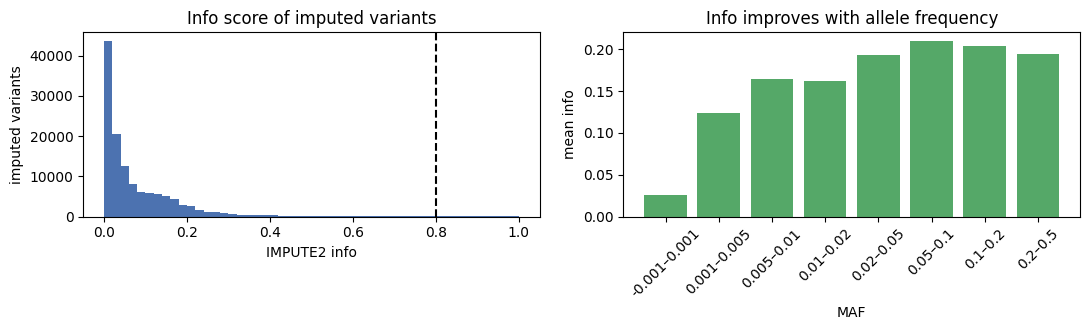

In [19]:
# 6.2  Variant counts and info score distribution
rows = []
for pre in prefixes:
    d = pd.read_csv(pre + ".gen_info", sep=r"\s+")
    d["typed"] = d["position"].isin(typed_set)
    rows.append(d[["position", "exp_freq_a1", "info", "certainty", "typed"]])
INFO = pd.concat(rows, ignore_index=True)
INFO["maf"] = np.minimum(INFO.exp_freq_a1, 1 - INFO.exp_freq_a1)
n_all, n_typed = len(INFO), int(INFO.typed.sum())
print(f"variants in region from ANGSD (kept)        : {len(kept):>9,}")
print(f"variants after imputation (panel sites)     : {n_all:>9,}   (×{n_all/max(len(kept),1):.1f})")
print(f"  of which imputed (not in ANGSD)           : {n_all-n_typed:>9,}")
print(f"  imputed with info ≥ 0.8                   : {int(((~INFO.typed)&(INFO['info']>=0.8)).sum()):>9,}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(INFO.loc[~INFO.typed, "info"].clip(0, 1), bins=50, color="#4C72B0"); ax[0].set_xlabel("IMPUTE2 info"); ax[0].set_ylabel("imputed variants")
ax[0].set_title("Info score of imputed variants"); ax[0].axvline(0.8, color="k", ls="--")
bins = [0, .001, .005, .01, .02, .05, .1, .2, .5]
INFO["mafbin"] = pd.cut(INFO.maf, bins, include_lowest=True)
m = INFO[~INFO.typed].groupby("mafbin", observed=True)["info"].mean()
ax[1].bar(range(len(m)), m.values, color="#55A868"); ax[1].set_xticks(range(len(m))); ax[1].set_xticklabels([f"{b.left:g}–{b.right:g}" for b in m.index], rotation=45)
ax[1].set_ylabel("mean info"); ax[1].set_xlabel("MAF"); ax[1].set_title("Info improves with allele frequency")
plt.tight_layout(); plt.show()

# Part 7 — Evaluation: how good is it?

Because our study individuals have **high-coverage (30×) genotypes in the NYGC callset**, we have a gold standard (`truth.vcf.gz`, prepared in 3.4; the individuals are *not* in the reference panel used for imputation).
A few caveats: the truth is not perfect either (≈ 99+% accurate), and its phase is statistical (trio-aided for the family members, otherwise inferred) – good enough for benchmarking.

## 7.1 Metrics

| Metric | Definition | Interpretation |
|---|---|---|
| **r² (dosage)** | squared Pearson correlation between imputed dosage and true genotype (0/1/2), pooled over the variants in an allele-frequency bin | the standard accuracy measure; independent of allele frequency prior knowledge; for GWAS an r² of 0.8 means a loss of ≈ 20% of effective sample size |
| **Concordance** | fraction of genotypes where the best-guess genotype equals the truth | inflated for rare variants (predicting `0/0` everywhere is “right” 99.9% of the time), so report it **by MAF bin** or as *non-reference concordance* |
| **IMPUTE2 `info`** | model-based accuracy estimate (no truth needed) | should track r²; check that in the calibration plot |
| **Switch error rate** | at consecutive heterozygous sites, fraction where the relative phase differs from the truth | phasing quality |

We evaluate (i) all **imputed** (untyped) variants, (ii) the **typed** ones, where we can compare the *raw ANGSD posterior dosage* with the final output – this shows what phasing + imputation add to the data you started with.

In [20]:
# 7.1  Load the truth (phased genotypes of the study samples from the high-coverage callset)
def load_truth(vcf, wanted_samples):
    # returns pos→row dict, alleles dict, haplotype matrices H1,H2 [sites × n_wanted] (int8; -1 missing), list of samples found
    names = run(f"bcftools query -l {vcf}", quiet=True).stdout.split()
    col = {s: i for i, s in enumerate(names)}
    sel = [s for s in wanted_samples if s in col]
    idx = np.array([col[s] for s in sel])
    pos_l, al, H1, H2 = [], {}, [], []
    p = subprocess.Popen(f"bcftools query -f '%POS\\t%REF\\t%ALT[\\t%GT]\\n' {vcf}", shell=True, executable="/bin/bash", stdout=subprocess.PIPE, text=True)
    for line in p.stdout:
        f = line.rstrip("\n").split("\t"); gts = f[3:]
        a = np.full(len(idx), -1, np.int8); b = np.full(len(idx), -1, np.int8)
        for k, j in enumerate(idx):
            g = gts[j]
            if len(g) >= 3 and g[0] in "01" and g[2] in "01": a[k], b[k] = int(g[0]), int(g[2])
        pos_l.append(int(f[0])); al[int(f[0])] = (f[1], f[2]); H1.append(a); H2.append(b)
    p.stdout.close(); p.wait()
    pos_l = np.array(pos_l)
    uniq = {int(p): i for i, p in enumerate(pos_l)}
    return uniq, al, np.array(H1), np.array(H2), sel

TRUTH_POS, TRUTH_AL, TH1, TH2, TRUTH_SAMPLES = load_truth(TRUTH_VCF, SAMPLES_PHASED)
print(f"truth: {TH1.shape[0]:,} variants × {TH1.shape[1]} individuals (of {len(SAMPLES_PHASED)} imputed)")
# column indices: imputed sample order → truth columns
tcol = {s: i for i, s in enumerate(TRUTH_SAMPLES)}
SEL_IMP = np.array([i for i, s in enumerate(SAMPLES_PHASED) if s in tcol])           # positions in imputed output
SEL_TRU = np.array([tcol[SAMPLES_PHASED[i]] for i in SEL_IMP])                       # positions in truth matrices
EVAL_SAMPLES = [SAMPLES_PHASED[i] for i in SEL_IMP]
TRUTH_G = np.where((TH1 >= 0) & (TH2 >= 0), TH1 + TH2, -1).astype(np.int8)

truth: 240,482 variants × 100 individuals (of 100 imputed)


In [21]:
# 7.2  Accumulate accuracy statistics (streaming over the IMPUTE2 output)
MAF_BINS = [0, .001, .005, .01, .02, .05, .1, .2, .5]
def maf_bin(maf):
    for k in range(len(MAF_BINS) - 1):
        if maf <= MAF_BINS[k + 1]: return k
    return len(MAF_BINS) - 2

class Acc:
    # pooled sums for a Pearson r² and concordance
    __slots__ = ("n", "sd", "sg", "sdd", "sgg", "sdg", "match", "nonref_n", "nonref_match")
    def __init__(self): [setattr(self, k, 0.0) for k in self.__slots__]
    def add(self, d, g, best):
        m = g >= 0
        d, g, best = d[m].astype(np.float64), g[m].astype(np.float64), best[m]
        self.n += len(g); self.sd += d.sum(); self.sg += g.sum(); self.sdd += (d*d).sum(); self.sgg += (g*g).sum(); self.sdg += (d*g).sum()
        self.match += (best == g).sum()
        nr = g > 0; self.nonref_n += nr.sum(); self.nonref_match += (best[nr] == g[nr]).sum()
    def r2(self):
        if self.n < 2: return np.nan
        cov = self.sdg - self.sd * self.sg / self.n
        vd = self.sdd - self.sd**2 / self.n; vg = self.sgg - self.sg**2 / self.n
        return cov**2 / (vd * vg) if vd > 1e-12 and vg > 1e-12 else np.nan
    def conc(self): return self.match / self.n if self.n else np.nan
    def nonref_conc(self): return self.nonref_match / self.nonref_n if self.nonref_n else np.nan

def evaluate_imputed(prefixes, typed_set):
    n_s = len(EVAL_SAMPLES); nb = len(MAF_BINS) - 1
    acc = {"imputed": [Acc() for _ in range(nb)], "typed": [Acc() for _ in range(nb)]}
    ib = np.linspace(0, 1, 11); acc_info = [Acc() for _ in range(10)]
    s_match = {"imputed": np.zeros(n_s), "typed": np.zeros(n_s)}; s_n = {"imputed": np.zeros(n_s), "typed": np.zeros(n_s)}
    nsites = Counter(); per_site = []
    for pre in prefixes:
        for pos, a0, a1, P, fq, info in stream_gen(pre + ".gen", pre + ".gen_info"):
            r = TRUTH_POS.get(pos)
            if r is None or TRUTH_AL[pos] != (a0, a1): nsites["no_truth"] += 1; continue
            g = TRUTH_G[r, SEL_TRU]
            P2 = P[SEL_IMP]; d = P2[:, 1] + 2 * P2[:, 2]; best = P2.argmax(axis=1)
            kind = "typed" if pos in typed_set else "imputed"
            mb = maf_bin(min(fq, 1 - fq)); acc[kind][mb].add(d, g, best); nsites[kind] += 1
            if kind == "imputed":
                acc_info[min(max(int(info * 10), 0), 9)].add(d, g, best)
            m = g >= 0; s_match[kind][m] += (best[m] == g[m]); s_n[kind][m] += 1
    return acc, acc_info, s_match, s_n, nsites

EVAL_FILE = f"{WORK}/eval_cache.pkl"
import pickle
if done(EVAL_FILE):
    ACC, ACC_INFO, S_MATCH, S_N, NS = pickle.load(open(EVAL_FILE, "rb"))
else:
    ACC, ACC_INFO, S_MATCH, S_N, NS = evaluate_imputed(prefixes, typed_set)
    pickle.dump((ACC, ACC_INFO, S_MATCH, S_N, NS), open(EVAL_FILE, "wb"))
print(dict(NS))

{'imputed': 126684, 'no_truth': 1900, 'typed': 21}


In [22]:
# 7.3  Accuracy by allele frequency: imputed variants and (for reference) the typed ones
lab = [f"{MAF_BINS[i]*100:g}–{MAF_BINS[i+1]*100:g}%" for i in range(len(MAF_BINS) - 1)]
tab = pd.DataFrame({
    "MAF bin": lab,
    "# imputed sites (pooled genotypes)": [int(a.n) for a in ACC["imputed"]],
    "r² imputed": [a.r2() for a in ACC["imputed"]],
    "concordance imputed": [a.conc() for a in ACC["imputed"]],
    "non-ref concordance imputed": [a.nonref_conc() for a in ACC["imputed"]],
    "r² typed (after SHAPEIT2+IMPUTE2)": [a.r2() for a in ACC["typed"]],
})
display(tab.style.format({c: "{:.3f}" for c in tab.columns if c.startswith(("r²", "conc", "non"))}).hide(axis="index"))
tab.to_csv(f"{OUTDIR}/accuracy_by_maf.csv", index=False)

MAF bin,# imputed sites (pooled genotypes),r² imputed,concordance imputed,non-ref concordance imputed,r² typed (after SHAPEIT2+IMPUTE2)
0–0.1%,7156200,0.395,0.999,0.151,nan
0.1–0.5%,2064000,0.422,0.994,0.195,nan
0.5–1%,749300,0.398,0.983,0.180,nan
1–2%,624200,0.349,0.968,0.161,nan
2–5%,579200,0.360,0.931,0.186,0.422
5–10%,375900,0.526,0.854,0.322,0.585
10–20%,396800,0.461,0.722,0.360,0.820
20–50%,722800,0.179,0.504,0.484,0.557


### 7.4 Baseline: what did the raw ANGSD posteriors give at the typed sites?

At the sites ANGSD *did* call, we can compare three versions of the genotype of each individual with the truth:

1. **ANGSD posterior dosage** `GP(0/1) + 2·GP(1/1)`, which is the original (alleles harmonised to the panel);
2. the **final** dosage after SHAPEIT2 (which fills in the missing hard calls and corrects errors using the phase) + IMPUTE2.

In [23]:
# 7.4  ANGSD posterior dosage at typed sites vs truth
def evaluate_angsd(study_vcf, panel_alleles, imputed_info):
    nb = len(MAF_BINS) - 1; acc = [Acc() for _ in range(nb)]
    freq = dict(zip(imputed_info.position, imputed_info.exp_freq_a1))
    idx = np.array([STUDY.index(s) for s in EVAL_SAMPLES])
    for pos, ref, alt, gp in iter_study(study_vcf):
        pa = panel_alleles.get(pos); r = TRUTH_POS.get(pos)
        if pa is None or r is None or pos not in freq: continue
        if (ref, alt) == pa: pass
        elif (ref, alt) == (pa[1], pa[0]): gp = gp[:, ::-1]
        else: continue
        gp = gp[idx]; ok = ~np.isnan(gp).any(axis=1)
        d = np.where(ok, gp[:, 1] + 2 * gp[:, 2], 0.0)
        g = np.where(ok, TRUTH_G[r, SEL_TRU], -1)
        best = np.where(ok, np.nanargmax(np.where(np.isnan(gp), -1, gp), axis=1), 0)
        f = freq[pos]; acc[maf_bin(min(f, 1 - f))].add(d, g, best)
    return acc
panel_alleles = load_panel_alleles(f"{REF_PREFIX}.legend.gz")
ACC_ANGSD = evaluate_angsd(STUDY_RAW, panel_alleles, INFO)
cmp_ = pd.DataFrame({"MAF bin": lab, "r² ANGSD GP dosage": [a.r2() for a in ACC_ANGSD],
                     "r² after SHAPEIT2+IMPUTE2 (typed)": [a.r2() for a in ACC["typed"]],
                     "r² imputed (untyped)": [a.r2() for a in ACC["imputed"]]})
display(cmp_.style.format({c: "{:.3f}" for c in cmp_.columns[1:]}).hide(axis="index"))

MAF bin,r² ANGSD GP dosage,r² after SHAPEIT2+IMPUTE2 (typed),r² imputed (untyped)
0–0.1%,nan,nan,0.395
0.1–0.5%,nan,nan,0.422
0.5–1%,nan,nan,0.398
1–2%,nan,nan,0.349
2–5%,0.067,0.422,0.360
5–10%,0.490,0.585,0.526
10–20%,0.948,0.820,0.461
20–50%,0.762,0.557,0.179


/tmp/ipykernel_1300/3885737008.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[2].boxplot([sc.loc[sc["pop"] == p, "conc_imputed"] for p in pops], labels=pops)


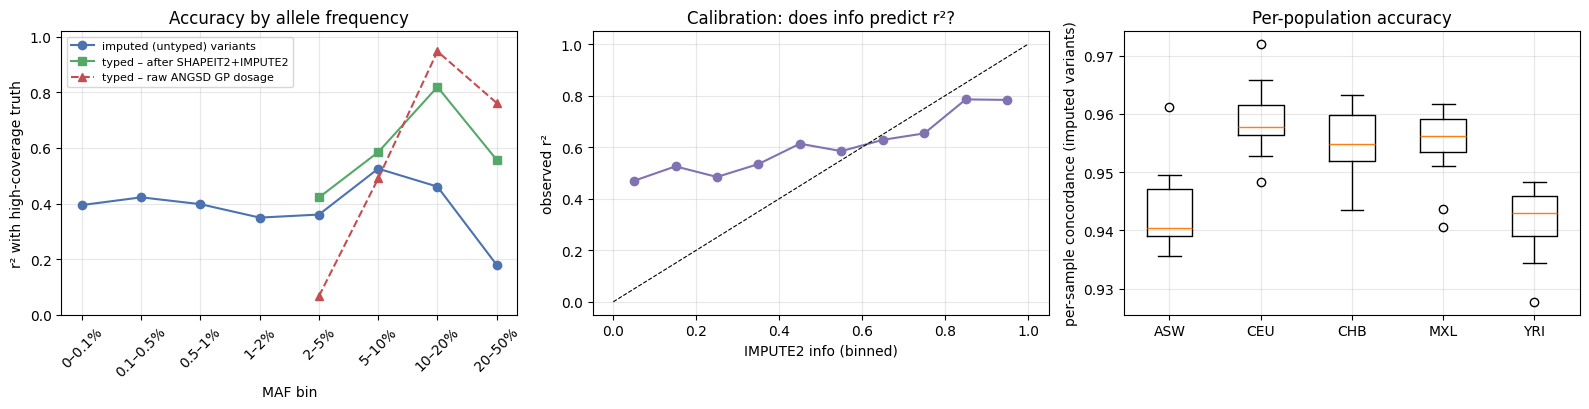

     count    mean
pop               
ASW     17  0.9428
CEU     25  0.9588
CHB     20  0.9555
MXL     18  0.9551
YRI     20  0.9418


In [24]:
# 7.5  Plots: accuracy vs MAF, info calibration, per-sample / per-population concordance
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(lab))
ax[0].plot(x, [a.r2() for a in ACC["imputed"]], "o-", label="imputed (untyped) variants", color="#4C72B0")
ax[0].plot(x, [a.r2() for a in ACC["typed"]], "s-", label="typed – after SHAPEIT2+IMPUTE2", color="#55A868")
ax[0].plot(x, [a.r2() for a in ACC_ANGSD], "^--", label="typed – raw ANGSD GP dosage", color="#C44E52")
ax[0].set_xticks(x); ax[0].set_xticklabels(lab, rotation=45); ax[0].set_ylim(0, 1.02); ax[0].set_ylabel("r² with high-coverage truth"); ax[0].set_xlabel("MAF bin")
ax[0].set_title("Accuracy by allele frequency"); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)

ci = [(i / 10 + .05, a.r2()) for i, a in enumerate(ACC_INFO) if a.n > 200]
ax[1].plot([c[0] for c in ci], [c[1] for c in ci], "o-", color="#8172B2"); ax[1].plot([0, 1], [0, 1], "k--", lw=.8)
ax[1].set_xlabel("IMPUTE2 info (binned)"); ax[1].set_ylabel("observed r²"); ax[1].set_title("Calibration: does info predict r²?"); ax[1].grid(alpha=.3)

sc = pd.DataFrame({"sample": EVAL_SAMPLES, "conc_imputed": S_MATCH["imputed"] / np.maximum(S_N["imputed"], 1)})
sc["pop"] = [POP.get(s, "NA") for s in sc["sample"]]
pops = sorted(sc["pop"].unique())
ax[2].boxplot([sc.loc[sc["pop"] == p, "conc_imputed"] for p in pops], labels=pops)
ax[2].set_ylabel("per-sample concordance (imputed variants)"); ax[2].set_title("Per-population accuracy"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUTDIR}/imputation_accuracy.png", dpi=150); plt.show()
print(sc.groupby("pop")["conc_imputed"].agg(["count", "mean"]).round(4).to_string())

**How to read these plots**

* **Left.** Common variants (MAF > 5%) are imputed very well (r² usually > 0.9) – the panel contains the haplotypes that tag them. Accuracy falls for rare variants: a variant seen only on a few reference haplotypes can only be
  imputed if the study individual shares *exactly* those haplotypes, and we also have fewer carriers in the study to measure the accuracy with (so the rare bins are noisy).
  The red dashed line is the raw ANGSD posterior at the same sites: **imputation also improves the genotypes you started with** because the HMM uses the haplotype structure to correct the noisy low-coverage genotypes.
* **Middle.** If the model were perfectly calibrated, points would lie on the diagonal. A common pattern is that `info` slightly overstates the accuracy for rare variants. Use `info ≥ 0.8` (a typical GWAS filter) *and* a minimum MAF.
* **Right.** Per-population accuracy. Populations less well represented in the panel or with more complex ancestry (admixed ASW, MXL) are typically a bit worse than YRI or CEU/CHB; the effect is larger for rarer variants.

## 7.6 Phasing quality: switch error rate

Compare the phase estimated by SHAPEIT2 from the **low-coverage** hard calls with the phase of the high-coverage callset at the typed sites. Only sites where both agree that the individual is heterozygous are used.

switch error rate over 346 consecutive heterozygous pairs: 24.566%   (mode: reference-assisted)


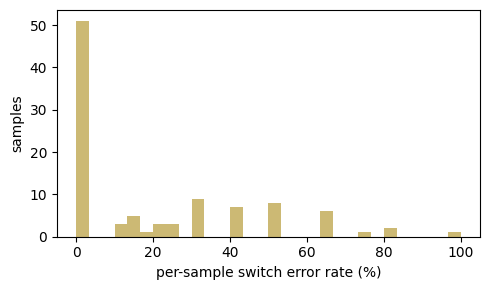

In [25]:
# 7.6  Switch error rate (SER) of phased.haps vs truth
def read_haps(path, wanted_samples, typed_positions=None):
    # returns positions, alleles, H [sites × 2n] int8
    pos, al, rows = [], [], []
    with open(path) as fh:
        for line in fh:
            f = line.split()
            pos.append(int(f[2])); al.append((f[3], f[4])); rows.append(np.array(f[5:], dtype=np.int8))
    return np.array(pos), al, np.array(rows)

def switch_error(ph_pos, ph_al, H, sel_imp, sel_tru, truth_pos, truth_al, th1, th2):
    keep = [i for i, (p, a) in enumerate(zip(ph_pos, ph_al)) if p in truth_pos and truth_al[int(p)] == a]
    rows = np.array([truth_pos[int(ph_pos[i])] for i in keep]); keep = np.array(keep)
    out = []
    for si, ti in zip(sel_imp, sel_tru):
        p1, p2 = H[keep, 2 * si], H[keep, 2 * si + 1]
        t1, t2 = th1[rows, ti], th2[rows, ti]
        het = (t1 >= 0) & (t2 >= 0) & (t1 != t2) & (p1 != p2)
        if het.sum() < 3: out.append((0, 0)); continue
        orient = (p1[het] == t1[het])
        out.append((int((orient[1:] != orient[:-1]).sum()), int(het.sum() - 1)))
    return out

ph_pos, ph_al, HH = read_haps(PHASED + ".haps", SAMPLES_PHASED)
sw = switch_error(ph_pos, ph_al, HH, SEL_IMP, SEL_TRU, TRUTH_POS, TRUTH_AL, TH1, TH2)
sw = np.array(sw); ser = sw[:, 0].sum() / max(sw[:, 1].sum(), 1)
print(f"switch error rate over {sw[:,1].sum():,} consecutive heterozygous pairs: {ser:.3%}   (mode: {'reference-assisted' if PHASE_WITH_REF else 'study-only'})")
per_s = sw[:, 0] / np.maximum(sw[:, 1], 1)
plt.figure(figsize=(5, 3)); plt.hist(per_s * 100, bins=30, color="#CCB974"); plt.xlabel("per-sample switch error rate (%)"); plt.ylabel("samples"); plt.tight_layout(); plt.show()

**Interpretation.** The typed sites are sparse (a few thousand per Mb at most, roughly 1 per 1–2 kb), and genotype errors in the hard calls (GP threshold) also show up here as “switches”. The SER from ANGSD hard calls of very-low-coverage data is therefore much higher than the 0.1–0.5%
typical of high-quality array/WGS genotypes. Try `PHASE_WITH_REF=False` (and delete `phased.*`, or `FORCE=True`) to see how much the reference helps, or raise `GP_CALL` to trade quantity for quality.

## 7.7 Save the summary

In [26]:
# 7.7  Summary table → Drive
summary = {
    "region": REGION, "n_study_samples": len(STUDY), "n_with_truth": len(EVAL_SAMPLES),
    "panel": os.path.basename(PANEL_VCF), "panel_individuals": n_hapcols // 2, "panel_snvs_in_region": n_ref,
    "genetic_map": MAP_SOURCE_USED or "cached", "hard_call_GP_threshold": GP_CALL,
    "typed_sites_kept": len(kept), "variants_after_imputation": n_all, "imputed_info_ge_0.8": int(((~INFO.typed) & (INFO["info"] >= 0.8)).sum()),
    "switch_error_rate": round(float(ser), 5),
    "r2_imputed_maf_gt_5pct": round(float(np.nanmean([ACC["imputed"][i].r2() for i in range(5, 8)])), 4),
}
json.dump(summary, open(f"{OUTDIR}/summary.json", "w"), indent=2)
INFO.to_csv(f"{OUTDIR}/info_scores.csv.gz", index=False)
print(json.dumps(summary, indent=2))
print("\nSaved to", OUTDIR, ":", sorted(os.listdir(OUTDIR)))

{
  "region": "chr22:20000000-30000000",
  "n_study_samples": 100,
  "n_with_truth": 100,
  "panel": "1kGP_high_coverage_Illumina.chr22.filtered.SNV_INDEL_SV_phased_panel.vcf.gz",
  "panel_individuals": 2767,
  "panel_snvs_in_region": 239243,
  "genetic_map": "shapeit4 repo (b38)",
  "hard_call_GP_threshold": 0.9,
  "typed_sites_kept": 21,
  "variants_after_imputation": 128605,
  "imputed_info_ge_0.8": 836,
  "switch_error_rate": 0.24566,
  "r2_imputed_maf_gt_5pct": 0.3885
}

Saved to /content/drive/MyDrive/GWAS/imputation_chr22_results : ['accuracy_by_maf.csv', 'imputation_accuracy.png', 'imputed_chr22_20000000_30000000.vcf.gz', 'imputed_chr22_20000000_30000000.vcf.gz.tbi', 'info_scores.csv.gz', 'summary.json']


# Part 8 — Discussion, limitations, and what to do with *your* organism

## 8.1 Lessons from this practical

1. **Imputation needs a matching reference panel.** The quality of the result is bounded by how well the panel represents the study individuals (ancestry, size, variant discovery).
2. **Data hygiene decides success.** Build, contig names, allele coding and strand must all agree; the harmonisation step in Part 3.5 and `shapeit -check` are not optional.
3. **Hard calls throw away information at low coverage.** SHAPEIT2/IMPUTE2 cannot take genotype likelihoods; we had to discard uncertain ANGSD calls (`GP_CALL`). For ≲ 5× data use likelihood-based methods (GLIMPSE2, QUILT, Beagle with GL, STITCH).
4. **Always validate.** Leave-out validation with known genotypes (as done here), or at least `info` scores and MAF-stratified reports, before putting imputed data in a GWAS.
5. **Use dosages in association testing**, not best-guess genotypes, and filter on `info`.

## 8.2 Using the imputed data for GWAS

* PLINK2: `--vcf imputed.vcf.gz dosage=DS` and `--glm`; SNPTEST/`-frequentist` can read `.gen` directly with the `-method score` / `expected`.
* Filter: `info ≥ 0.8` (0.3 for exploratory work), MAF ≥ 1% (smaller for large cohorts).
* Remember that the number of independent tests did not increase as much as the number of variants – LD matters for multiple-testing thresholds.

## 8.3 Practical advice for non-model organisms

| Situation | What to do |
|---|---|
| A haplotype panel exists for the species | convert it to the required format (`bcftools convert --haplegendsample`), use a species-specific genetic map (or LD-based/uniform map as an approximation), follow this notebook |
| Only low-coverage data, no panel | self-imputation: Beagle (genotype likelihoods), STITCH or QUILT; accuracy depends on sample size (≥ a few hundred individuals), ploidy and recombination rate |
| Few high-coverage individuals + many low-coverage | build the panel from the high-coverage ones: call → phase (SHAPEIT/Beagle/WhatsHap read-backed) → use as reference |
| Human data from a different build | lift over the panel or—better—re-align to the panel's build (as done in this course) |
| No genetic map | uniform map (`cM = Mb`) works with reduced accuracy; estimate from LD with e.g. `LDhat` or `pyrho`, or lift-over from a related species |

> A **human** reference panel cannot be used for any other species. It can only be used to *practice* the workflow, as we did here.

## 8.4 Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| Very low overlap between ANGSD sites and the panel | build mismatch or different contig coordinates | verify both are hg38; check `bcftools query -f '%POS %REF %ALT'` on both |
| Many `allele_mismatch` | ANGSD VCF with `N` as REF or strand mismatch | re-run ANGSD with `-ref hg38.fa` or `-doMajorMinor 4` |
| `shapeit` “segmentation fault” or crashes on gz VCF | old htslib in the binary | the notebook retries with an uncompressed VCF; otherwise convert to `.haps/.sample` via `bcftools convert --haplegendsample` |
| `impute2` says “ERROR: no genetic map” or odd positions | map not in chromosome coordinates of the data | rebuild the map (3.3) |
| Accuracy much lower than shown | few typed sites (`GP_CALL` too high or `-minInd` too strict) | lower `GP_CALL` to 0.8, or relax ANGSD filters |
| Colab disconnects | the free tier times out | re-run from the top: downloads (panel/map) are cached on Drive and finished steps are skipped |

## 8.5 Suggested exercises

1. Change `GP_CALL` to 0.7 and 0.99. How do the number of typed genotypes, the switch error rate and r² of the imputed variants change?
2. Set `MAX_STUDY = 30` vs `300`. Does the number of study individuals affect imputation accuracy (hint: phasing without a panel vs with)?
3. Change `K_HAP` to 100 and 1000; measure time and accuracy.
4. Impute with a *wrong* map (flat map, or hg19-based) – how bad is it?
5. Rerun with `PHASE_WITH_REF = False`. How much worse is phasing?
6. Impute only individuals of one population (e.g. YRI) with a panel that excludes YRI. Why is accuracy lower?
7. Compare with a modern tool (GLIMPSE2 or Beagle 5) on the *same* ANGSD likelihoods.

## 8.6 References

* Li N & Stephens M (2003) *Genetics* 165:2213 – the copying model.
* Delaneau O, Marchini J, Zagury JF (2012) *Nature Methods* 9:179 – SHAPEIT2 (linear complexity phasing); Delaneau et al. (2013) *Nature Methods* 10:5 – haplotype estimation with reference panels.
* Howie B, Donnelly P, Marchini J (2009) *PLoS Genet* 5:e1000529 – IMPUTE2; Howie B et al. (2012) *Nature Genetics* 44:955 – pre-phasing.
* Byrska-Bishop M et al. (2022) *Cell* 185:3426 – the NYGC 30× 1000 Genomes data.
* Rubinacci S et al. (2021) *Nature Genetics* 53:120 – GLIMPSE.
* Browning BL et al. (2018) *AJHG* 103:338 – Beagle 5.

In [27]:
!jupyter nbconvert --to html /content/drive/MyDrive/GWAS/Phasing_Imputation_SHAPEIT2_IMPUTE2_1000G_chr22_Colab.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/GWAS/Phasing_Imputation_SHAPEIT2_IMPUTE2_1000G_chr22_Colab.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 966726 bytes to /content/drive/MyDrive/GWAS/Phasing_Imputation_SHAPEIT2_IMPUTE2_1000G_chr22_Colab.html
